<a href="https://colab.research.google.com/github/PacktPublishing/Hands-On-Open-Source-Foundation-Models-for-Time-Series-Forecasting/blob/main/Chapter03_Zero_Shot_Forecasting/bonus/B05a_zero_shot_chronos_timesfm_tirex.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook B05a · Zero-shot forecasting with Chronos, TimesFM and TiRex (bonus datasets)

*Hands-On Open-Source Foundation Models for Time Series Forecasting*, Chapter 3: Zero-Shot Forecasting in Practice

This notebook runs Amazon's Chronos-2 and Chronos-Bolt, Google's TimesFM-2.5 and TimesFM-3, and NX-AI's TiRex and TiRex-2 zero-shot: the models forecast our series straight away, without any training on
our data. Each model forecasts every dataset, every horizon (7, 14, 30, 60 and 90 trading days) and every rolling window fixed in
Notebook 04.

For each model you will find a figure of its architecture, a plain description of how it works and what is new
about it, what it costs to run, and which covariates it can read without fine-tuning. The figures were checked
against each model's paper, its released configuration and the network as loaded.

#### Why these models share a notebook

They install into the same Python environment (`requirements/env-core.txt`). Foundation-model libraries pin
different versions of `torch`, `numpy` and `transformers`, and these often clash, so the chapter groups the models
by the environment they need rather than by the company that made them.

The datasets are the two bonus ones: B1, the WTI crude oil price (trading days, one series), and B2, the US Treasury yield curve (trading days, five maturities). Notebooks 05a to 09b run the same models on D1 to D4.

**What you will learn**

- what is inside each model, drawn layer by layer in one consistent style, with the maths of each layer explained
- which models can use past-only and known-future covariates without fine-tuning, and how they do it
- how the models' point forecasts compare across datasets and horizons, by MASE and by RMSE, and what they cost
  to run on a CPU
- how the forecasts look against the actual values at every horizon

| Environment and compute | |
|---|---|
| Python | 3.12 (tested); see *How to run* for Colab |
| Packages | [`requirements/env-core.txt`](../requirements/env-core.txt) (pinned) |
| Hardware | CPU only; a GPU is used automatically if present |
| Network | downloads the checkpoints from Hugging Face on first use |
| Run time, quick check (default) | about 3 min of forecasting on 4 CPU cores (Colab's free tier has 2 cores: allow about twice as long) |
| Run time, `FULL_RUN = True` | about 6 min of forecasting with one CPU thread, while other notebooks shared the machine |
| Peak memory | 0.9 GB above the kernel's baseline (largest single call) |

**How to run this notebook**

- **Google Colab:** choose *Runtime > Run all*. The first code cell fetches this chapter's folder and installs `requirements/env-core.txt`
  with uv (a few minutes the first time). If it says it is restarting the session, wait, then choose *Runtime > Run all*
  again. To use your own copy on Google Drive, set `DRIVE_COPY` in that cell to the folder's path. A GPU runtime
  is not needed; if you pick one, the models use it.
- **Your own computer (Cursor, VS Code or Jupyter):** create the environment once with
  `uv venv .venv-core -p 3.12 && uv pip install -p .venv-core -r requirements/env-core.txt`
  (or `python3.12 -m venv .venv-core` and `pip install -r ...`), open this folder, choose the `.venv-core` kernel
  and run all cells.

In [1]:
# Setup: find this chapter's folder (on Colab: fetch it and install this notebook's environment)
import os
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules


def is_chapter(d):
    return (Path(d) / "src" / "ch03_dataprep" / "__init__.py").is_file()


if IN_COLAB:  # get this chapter's folder and install this notebook's environment
    import shutil

    CHAPTER = "Chapter03_Zero_Shot_Forecasting"   # this chapter's folder in the book's repository
    DRIVE_COPY = ""   # optional: path of your own copy of this folder on Google Drive (skips GitHub)
    BOOK = Path("/content/book")

    def chapter_dir():  # this chapter's folder under /content/book, or None until it is there
        return next((d for d in (BOOK / CHAPTER, BOOK) if is_chapter(d)), None)

    def find_in_drive(top="/content/drive/MyDrive", depth=6):  # the copies of CHAPTER, shallowest first
        level = [top]
        for _ in range(depth):
            subdirs = []
            for d in level:
                try:
                    subdirs += [e.path for e in os.scandir(d) if e.is_dir() and not e.name.startswith(".")]
                except OSError:
                    pass
            hits = [d for d in subdirs if Path(d).name == CHAPTER and is_chapter(d)]
            if hits:
                return hits
            level = subdirs
        return []

    def local_only(d, names):  # what not to copy from Drive: local environments, caches, downloaded data
        return [n for n in names if n.startswith(".venv") or n == "__pycache__" or (d.endswith("/data") and n == "raw")]

    if chapter_dir() is None and not DRIVE_COPY:    # 1) clone the book's repository from GitHub
        shutil.rmtree(BOOK, ignore_errors=True)
        !GIT_TERMINAL_PROMPT=0 git clone -q --depth 1 https://github.com/PacktPublishing/Hands-On-Open-Source-Foundation-Models-for-Time-Series-Forecasting /content/book
    if chapter_dir() is None:                       # 2) not on GitHub (yet): copy it from your Google Drive
        from google.colab import drive
        drive.mount("/content/drive")
        if not DRIVE_COPY:
            print(f"{CHAPTER} is not on GitHub: searching My Drive for it (set DRIVE_COPY above to skip this)")
            hits = find_in_drive()
            if len(hits) > 1:
                raise FileExistsError(f"several copies of {CHAPTER} in My Drive: {hits}. Set DRIVE_COPY to one.")
            DRIVE_COPY = hits[0] if hits else ""
        if DRIVE_COPY and not is_chapter(DRIVE_COPY):
            raise FileNotFoundError(f"DRIVE_COPY = {DRIVE_COPY!r} is not this chapter's folder (no src/ch03_dataprep)")
        if DRIVE_COPY:
            print(f"copying {DRIVE_COPY} to {BOOK / CHAPTER} ...")
            shutil.rmtree(BOOK, ignore_errors=True)
            shutil.copytree(DRIVE_COPY, BOOK / "partial-copy", ignore=local_only)
            (BOOK / "partial-copy").rename(BOOK / CHAPTER)    # only a finished copy gets the chapter's name
            print(f"copied {sum(len(files) for _, _, files in os.walk(BOOK / CHAPTER)):,} files")
    if chapter_dir() is None:
        raise FileNotFoundError(f"{CHAPTER} is not in the book's GitHub repository or in your Google Drive. "
                                "Upload the folder to Drive, or set DRIVE_COPY above to its path there.")
    os.chdir(chapter_dir())
    import importlib.metadata as md

    def key(name):  # package installers treat huggingface_hub and huggingface-hub as one package
        return name.lower().replace("_", "-").replace(".", "-")

    def versions():  # the version of every installed package, as Python finds it (first copy on sys.path)
        found = {}
        for d in md.distributions():
            found.setdefault(key(d.metadata["Name"]), d.version)
        return found

    before = versions()
    # Install with uv: it downloads and installs packages in parallel, several times faster than pip. Colab comes
    # with uv (installed here if not). The settings point uv at Colab's own Python (Colab has no virtual environment)
    # and drop install constraints that Colab may have left over from building its image. Each uv line falls back
    # to pip if uv fails.
    if shutil.which("uv") is None:
        %pip install -q uv
    for name in ("UV_CONSTRAINT", "UV_BUILD_CONSTRAINT", "UV_PRERELEASE"):
        os.environ.pop(name, None)
    os.environ.update(UV_PYTHON=sys.executable, UV_SYSTEM_PYTHON="1", UV_BREAK_SYSTEM_PACKAGES="1")
    # keep Colab's own torch (with CUDA) and Jupyter; install everything else this notebook needs
    !grep -vE "^(torch|jupyter|ipykernel|nbclient|nbformat|pytest|nbval|ruff)==" requirements/env-core.txt > /tmp/requirements-colab.txt
    !uv pip install -q -r /tmp/requirements-colab.txt || {sys.executable} -m pip install -q -r /tmp/requirements-colab.txt
    # stop here if neither uv nor pip could install everything; the error message is above
    try:
        from packaging.version import Version
    except ImportError:
        Version = str
    missing = []
    for line in open("/tmp/requirements-colab.txt"):
        name, _, pin = line.split("#")[0].strip().partition("==")
        if not pin:
            continue
        try:
            installed = md.version(name.split("[")[0])
        except md.PackageNotFoundError:
            installed = None
        if installed is None or Version(installed) != Version(pin):
            missing.append(f"{name}=={pin}")
    if missing:
        raise RuntimeError(f"Could not install {', '.join(missing)}; scroll up for its error. If it was a network error, "
                           "run this cell again. If uv or pip tried to build a package from source, this runtime's Python is "
                           "too new for this notebook: see the How to run section at the top.")
    # Colab comes with torchvision, torchaudio, torchcodec and transformers, and torchmetrics imports some of them
    # whenever they are installed. If the install changed a package they depend on (some environments replace torch or
    # huggingface-hub), they no longer load. This notebook does not need them, so remove those that broke.
    try:
        from packaging.requirements import Requirement
    except ImportError:  # Colab has packaging; pip always carries its own copy
        from pip._vendor.packaging.requirements import Requirement

    now = versions()
    changed = {name for name, version in now.items() if before.get(name) != version}
    if "torch" in changed:
        # This notebook needs another torch than Colab's (Notebook 06: 2.4.1). Replacing torch can leave some of the
        # old torch's files behind, and Python then loads them ("cannot import name ... from torch.onnx"). Reinstall
        # it into clean folders (uv takes it from its cache, so nothing downloads twice).
        print(f"Replacing Colab's torch {before.get('torch')} with {now['torch']}: reinstalling it into clean folders ...")
        torch_pin = now["torch"]
        site = Path(md.distribution("torch").locate_file(""))
        folders = [site / m for m, names in md.packages_distributions().items()
                   if "torch" in names and m.isidentifier() and (site / m).is_dir()]
        !uv pip uninstall -q torch || {sys.executable} -m pip uninstall -q -y torch
        for folder in folders:
            shutil.rmtree(folder, ignore_errors=True)
        !uv pip install -q torch=={torch_pin} || {sys.executable} -m pip install -q torch=={torch_pin}
        now = versions()

    def requirements(dist):  # the requirements of an installed package that apply here
        found = []
        for line in md.requires(dist) or []:
            try:
                r = Requirement(line)
                if r.marker is None or r.marker.evaluate({"extra": ""}):
                    found.append(r)
            except Exception:  # a line this version of packaging cannot read
                pass
        return found

    def broken(dist):  # Colab's copy of dist, and the install changed something it needs
        if dist not in now or dist in changed:
            return False  # not installed, or installed by this notebook
        if "torch" in changed:
            return True   # Colab built and tested it with its own torch
        return any(key(r.name) in changed and not r.specifier.contains(now[key(r.name)], prereleases=True)
                   for r in requirements(dist))

    misfits = [d for d in ("torchvision", "torchaudio", "torchcodec", "transformers") if broken(d)]
    if misfits:
        print(f"Removing unused packages that this install broke: {', '.join(misfits)}")
        !uv pip uninstall -q {" ".join(misfits)} || {sys.executable} -m pip uninstall -q -y {" ".join(misfits)}
    # Colab imports some packages (numpy, pandas, torch, ...) before this cell finishes. If the install replaced one
    # of them, Python keeps the old version in memory and mixes it with the new files on disk (errors such as
    # "cannot import name ... from torch.onnx"), so restart once to load the new version.
    after = versions()
    stale = sorted(m for m, names in md.packages_distributions().items() if m in sys.modules
                   and any(before.get(key(n), after.get(key(n))) != after.get(key(n)) for n in names))
    for m in ("torch", "numpy", "pandas", "scipy"):  # also catches a session that was not restarted after an earlier run
        loaded = str(getattr(sys.modules.get(m), "__version__", ""))
        if loaded and m not in stale and loaded.split("+")[0] != after.get(m, loaded).split("+")[0]:
            stale.append(m)
    restarted_from = Path("/tmp/ch03_restart_pid")   # the session this cell last asked to restart
    if stale and restarted_from.is_file() and restarted_from.read_text() == str(os.getpid()):
        raise SystemExit(f"The session has not restarted and still has the old {', '.join(stale)} in memory. "
                         "Choose Runtime > Restart session, then Runtime > Run all.")
    if stale:
        restarted_from.write_text(str(os.getpid()))
        print(f"The install updated {', '.join(stale)}, which Colab had already loaded: restarting the session.")
        from IPython import get_ipython
        kernel = getattr(get_ipython(), "kernel", None)
        if kernel is not None:
            kernel.do_shutdown(True)
        raise SystemExit("When the session has restarted, choose Runtime > Run all again; the first cell then finishes quickly. "
                         "If it has not restarted after a few seconds, choose Runtime > Restart session, then Runtime > Run all.")
import torch

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if is_chapter(p))
sys.path.insert(0, str(ROOT / "src"))
os.chdir(ROOT)
DATA, RESULTS, INPUT = ROOT / "data", ROOT / "results", ROOT / "input_timeseries"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"chapter folder: {ROOT}  |  Python {sys.version.split()[0]}  |  Colab: {IN_COLAB}  |  device: {DEVICE}")

chapter folder: /home/user/fresh/repo/Chapter03_Zero_Shot_Forecasting  |  Python 3.12.13  |  Colab: False  |  device: cpu


#### Quick check or full run

With `FULL_RUN = False`, the default, each model makes a quick check: it forecasts the fixed-origin window at the
two shortest horizons of every dataset. That is enough to show that the model installs and runs on your machine.
The analysis then reads the stored results of the full runs (every horizon and every rolling window) from
`results/forecasts/`. Set `FULL_RUN = True` to recompute those full results yourself.

In [2]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from ch03_dataprep.plotting import set_style
from ch03_zeroshot.architectures import figure
from ch03_zeroshot.capabilities import capability_table
from ch03_zeroshot.data import load_frame
from ch03_zeroshot.models import get_model
from ch03_zeroshot.report import (cost_table, forecast_gallery, gain_tables, load_forecasts, run_table,
                                  scores_cached, show_forecast_tables, show_gains, show_horizon_table)
from ch03_zeroshot.metrics import aggregate
from ch03_zeroshot.runner import quiet_logs, run_model, run_summary
from ch03_zeroshot.tables import display_names

warnings.filterwarnings("ignore")
quiet_logs()   # keep the libraries' routine INFO messages out of the outputs; warnings still show
set_style()
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 30)

FULL_RUN = False                       # True: recompute every horizon and window (see the table above)
MODELS = ['chronos2', 'chronos-bolt', 'timesfm25', 'timesfm3', 'tirex', 'tirex2']
DATASETS = ['B1', 'B2']
NAMES = display_names()
FIG = RESULTS / "figures" / "architectures"
FIG.mkdir(parents=True, exist_ok=True)


def forecast(key):
    """Run one model (quick check or full run) and show what it read and how long it took."""
    log = run_model(key, DATASETS, ROOT, smoke=not FULL_RUN, verbose=False)
    print(f"{log['name']} ({log['checkpoint']}): {(log['parameters'] or 0) / 1e6:.1f}M parameters, "
          f"loaded in {log['load_seconds']} s")
    return run_table(log, DATASETS)

## 1 · The models in this notebook

The table lists each model with the organisation that released it, the kind of network it is built on, its size
and the licence of its weights. A few terms come up again and again in the model descriptions that follow:

- A **token** is the piece of input a network handles as one unit. Most models cut a series into **patches**,
  short windows of consecutive values (16 or 32 steps, for example), and turn each patch into one token, so a long
  context becomes a short sequence.
- **Attention** lets every token look at the other tokens and take in the ones that matter for it. Its cost grows
  with the square of the number of tokens, which is why patching helps. **Recurrent** and **state-space** layers
  instead carry a running memory along the sequence, so their cost grows only in proportion to its length.
- An **encoder** reads the whole context at once. A **decoder-only** model, like the GPT language models, reads
  the tokens in time order and predicts what comes next.
- **Time attention** works along one series. **Variate attention** (also called group attention) works across the
  series at the same time step; that is how a model reads several targets, or a target and its covariates,
  together.
- A **quantile forecast** gives several values for each future step, for example the 10 %, 50 % and 90 %
  quantiles, instead of a single number. The median (the 50 % quantile) is the point forecast scored in this
  chapter.
- In the cost notes, $T$ is the context length, $H$ the horizon, $N$ the number of tokens, $d$ the width of a token
  vector, $L$ the number of layers and $V$ the number of rows (targets plus covariates). $O(N^2 d)$ means that
  doubling the number of tokens roughly quadruples the work.

| Model | Organisation | Backbone | Parameters | Checkpoint | Licence |
|---|---|---|---|---|---|
| Chronos-2 | Amazon | encoder-only transformer | 119.5M | `amazon/chronos-2` | Apache-2.0 |
| Chronos-Bolt (small) | Amazon | T5 encoder-decoder | 47.7M | `amazon/chronos-bolt-small` | Apache-2.0 |
| TimesFM-2.5 | Google | decoder-only transformer | 231.3M | `google/timesfm-2.5-200m-pytorch` | Apache-2.0 |
| TimesFM-3 | Google | decoder-only transformer with variate attention | 330.7M | `google/timesfm-3.0-pytorch` | timesfm-non-commercial-license-v1.0 (weights); Apache-2.0 (code) |
| TiRex | NX-AI | xLSTM (sLSTM) decoder | 35.3M | `NX-AI/TiRex` | NXAI Community License |
| TiRex-2 | NX-AI | xLSTM time mixer + variate mixer | 82.5M | `NX-AI/TiRex-2` | Apache-2.0 |

In [3]:
capability_table().set_index("key").loc[MODELS, ["model", "multivariate", "past_covariates", "future_covariates",
                                                 "exogenous_class", "how"]]

,model,multivariate,past_covariates,future_covariates,exogenous_class,how
key,,,,,,
chronos2,Chronos-2,True,True,True,past + known-future covariates,group attention across target and covariate to...
chronos-bolt,Chronos-Bolt (small),False,False,False,none (target only),univariate only
timesfm25,TimesFM-2.5,False,False,True,known-future covariates only,XReg: in-context linear regression on the cova...
timesfm3,TimesFM-3,True,True,True,past + known-future covariates,variate attention over target and covariate ch...
tirex,TiRex,False,False,False,none (target only),univariate only
tirex2,TiRex-2,True,True,True,past + known-future covariates,asymmetric group attention; reverse xLSTM pass...


## 2.1 · Chronos-2 (Amazon)

Chronos-2 is an encoder-only transformer. It lays out every series of a forecasting problem, targets and covariates alike, as separate rows of patches, and its blocks alternate between two kinds of attention: time attention, which looks along one row, and group attention, which looks across the rows at the same time step. Thanks to this layout, the same weights handle a single series, several series together, or a series with covariates, all in context and without fine-tuning. The future is part of the input too: the patches after the forecast origin carry the known-future covariates and a mask for everything still unknown, and a residual output head turns them into 21 quantiles in a single pass.

#### How to read the figure

Read the figure from left to right. Its four numbered panels follow the data from the series the model reads to the forecast it returns. The bold sentence under the panels sums up what sets the model apart, and the grey lines below give its size and main settings, then how this chapter's notebooks run it.

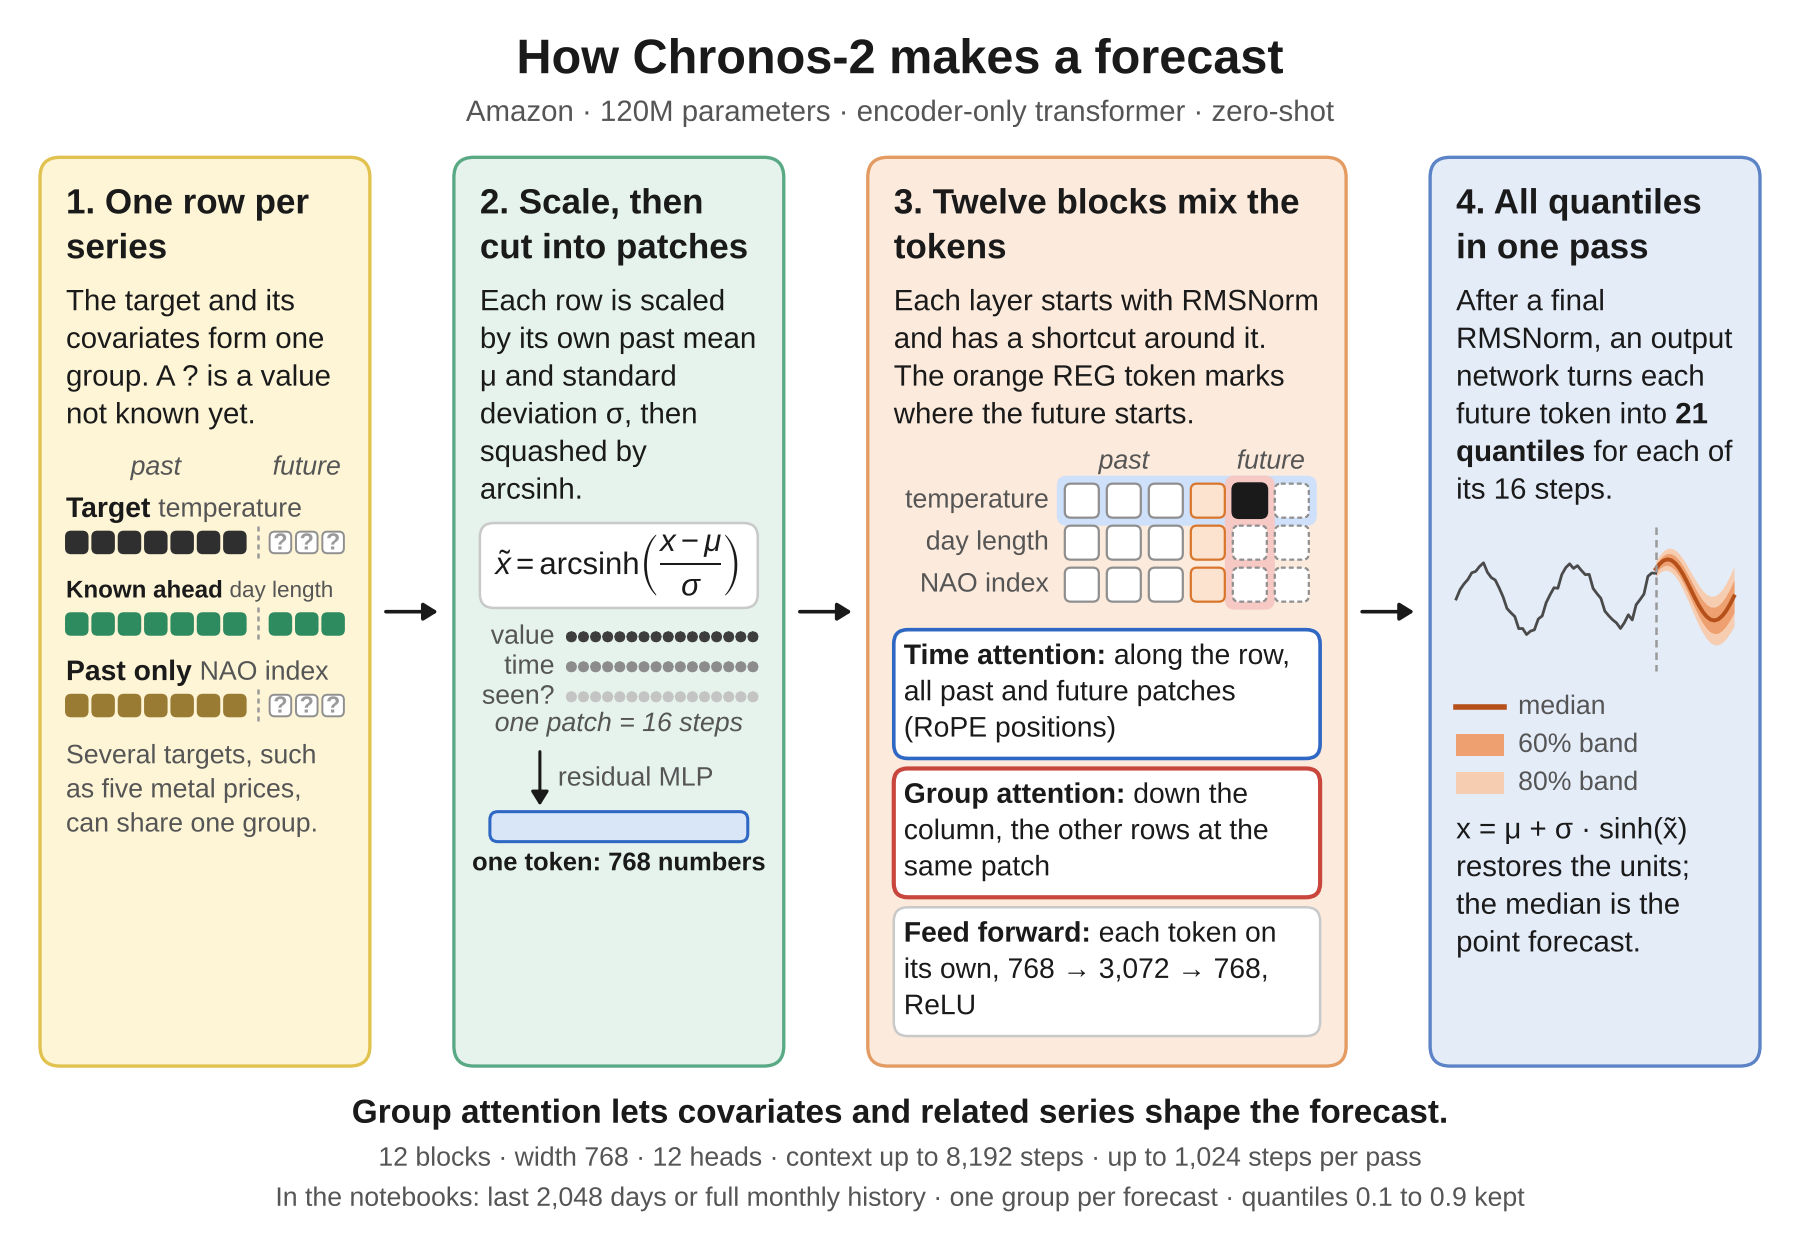

In [4]:
fig = figure("chronos2", path=FIG / "chronos2.png")

#### The maths behind the figure

The figure names the model's main components. Their equations follow, in the order in which the data passes through them.

The input is first **standardised** with the mean $\mu$ and standard deviation $\sigma$ of the context (in the causal versions, of the values seen so far), and then compressed with the **inverse hyperbolic sine** (arcsinh):

$$\tilde{x}_ t=\mathrm{arcsinh}\left(\frac{x_t-\mu}{\sigma}\right)$$

The arcsinh is close to a straight line near zero and grows like a logarithm for large values, so a few spikes cannot dominate the input.

**Patching** cuts the series into windows of $P$ steps, and each window becomes one token:

$$p_i=(\tilde{x}_ {(i-1)P+1},\dots,\tilde{x}_ {iP})$$

A context of $T$ steps then gives $T/P$ tokens, so attention costs $(T/P)^2$ instead of $T^2$.

The **patch embedding** turns each patch (with its missing-value mask, where the model has one) into a vector of width $d$, the token the transformer works on:

$$h_i=\mathrm{MLP}(p_i)$$

The map is a small fully connected network, a multilayer perceptron (MLP).

The **quantile head** has one output per quantile level $\tau$. Training minimises the pinball loss $\rho_\tau$ of the error $u=y-\hat{q}_ \tau$:

$$\rho_\tau(u)=\max(\tau u,\thinspace(\tau-1)u)$$

Minimising this loss makes each output the $\tau$-quantile of the forecast distribution. The median ($\tau=0.5$) is the point forecast scored in this chapter.

**RMSNorm** divides each token vector $h$ by its root mean square and multiplies the result by a learned gain $g$:

$$\frac{h}{\sqrt{\frac{1}{d}\sum_j h_j^2+\epsilon}}\odot g$$

Here $d$ is the width of the vector and $\epsilon$ a small constant that avoids dividing by zero. The normalisation keeps the size of the activations stable through many layers.

**T5-style attention with rotary positions** (RoPE) rotates the queries and keys by an angle proportional to their position before comparing them; the rotated versions are written $\tilde{Q}$ and $\tilde{K}$:

$$\mathrm{softmax}\left(\tilde{Q}\tilde{K}^{\top}\right)V$$

Each score then depends on the distance between the two tokens. As in T5, the scores are not divided by $\sqrt{d_k}$. The group attention in the figure uses the same unscaled form, without the rotation.

The **feed-forward network** widens each token with $W_1$, keeps the positive part (ReLU) and projects it back with $W_2$:

$$W_2\thinspace\max(0,\thinspace W_1h)$$

It works on every token separately, after attention has mixed them.

#### What it costs to run

Each block costs about O(V · N² · d) for time attention, with V rows of N = (T + H)/16 patches, plus O(N · V² · d) for group attention. One forward pass covers the whole horizon, up to 64 output patches (1,024 steps). The loaded network has 119.5M parameters.

#### Covariates

Without fine-tuning, Chronos-2 can forecast several target series jointly and read both past-only and known-future covariates. Group attention lets the target tokens attend to the covariate tokens at the same time step.

#### Where the figure comes from

The figure was checked against the model's paper, its released code and configuration, and the code this chapter
runs. The main sources for its components:

| Component in the figure | Source |
|---|---|
| encoder-only, T5 encoder design | Ansari et al. 2025, Sec. 3.2 |
| standardisation, then arcsinh | Sec. 3.1, Eq. 1-2 |
| patch + time index + mask, residual network from 3P inputs to width D | Sec. 3.1, Eq. 3 |
| REG token between context and future patches | Sec. 3.1 |
| time attention uses RoPE; group attention has no positional embedding | Sec. 3.2 |
| 21 quantiles 0.01..0.99 | Sec. 3.2 Quantile Head |
| block = TimeSelfAttention, GroupSelfAttention, FeedForward, each pre-norm + residual | chronos 2.3.2 chronos2/model.py Chronos2EncoderBlock |
| output residual block 768 → 336 = 16 × 21 | loaded module tree |

#### The code

This chapter's adapter for Chronos-2 is the class `Chronos2` in [`src/ch03_zeroshot/models/chronos.py`](../src/ch03_zeroshot/models/chronos.py) (line 27): it loads the checkpoint [`amazon/chronos-2`](https://huggingface.co/amazon/chronos-2), hands the model our context (and the covariates it can read) and turns its output into quantiles. All adapters share the interface `ZeroShotForecaster` in [`models/base.py`](../src/ch03_zeroshot/models/base.py), and `run_model` in [`runner.py`](../src/ch03_zeroshot/runner.py) runs it over every dataset, horizon and window. The network itself, layer by layer, is implemented in the `chronos-forecasting` 2.3.2 library ([PyPI page](https://pypi.org/project/chronos-forecasting/2.3.2/)). The figure above is drawn by [`architectures.py`](../src/ch03_zeroshot/architectures.py).

In [5]:
forecast("chronos2")

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 170/170 [00:00<00:00, 5432.21it/s]

Chronos-2 (amazon/chronos-2): 119.5M parameters, loaded in 2.9 s


,status,seconds,covariates read,notes
dataset,,,,
B1,ran,6.5,none,
B2,ran,38.2,none,


## 2.2 · Chronos-Bolt (small) (Amazon)

Chronos-Bolt is the faster successor of the original Chronos. The original model scaled each value into one of 4,096 bins, treated the bins as words and generated the forecast one token at a time, like a language model. Chronos-Bolt instead feeds patches of real values to a T5 encoder, and its decoder writes 64 steps of 9 quantiles in a single step. It is univariate: each series is forecast on its own.

#### How to read the figure

Read the figure from left to right. Its four numbered panels follow the data from the series the model reads to the forecast it returns. The bold sentence under the panels sums up what sets the model apart, and the grey lines below give its size and main settings, then how this chapter's notebooks run it.

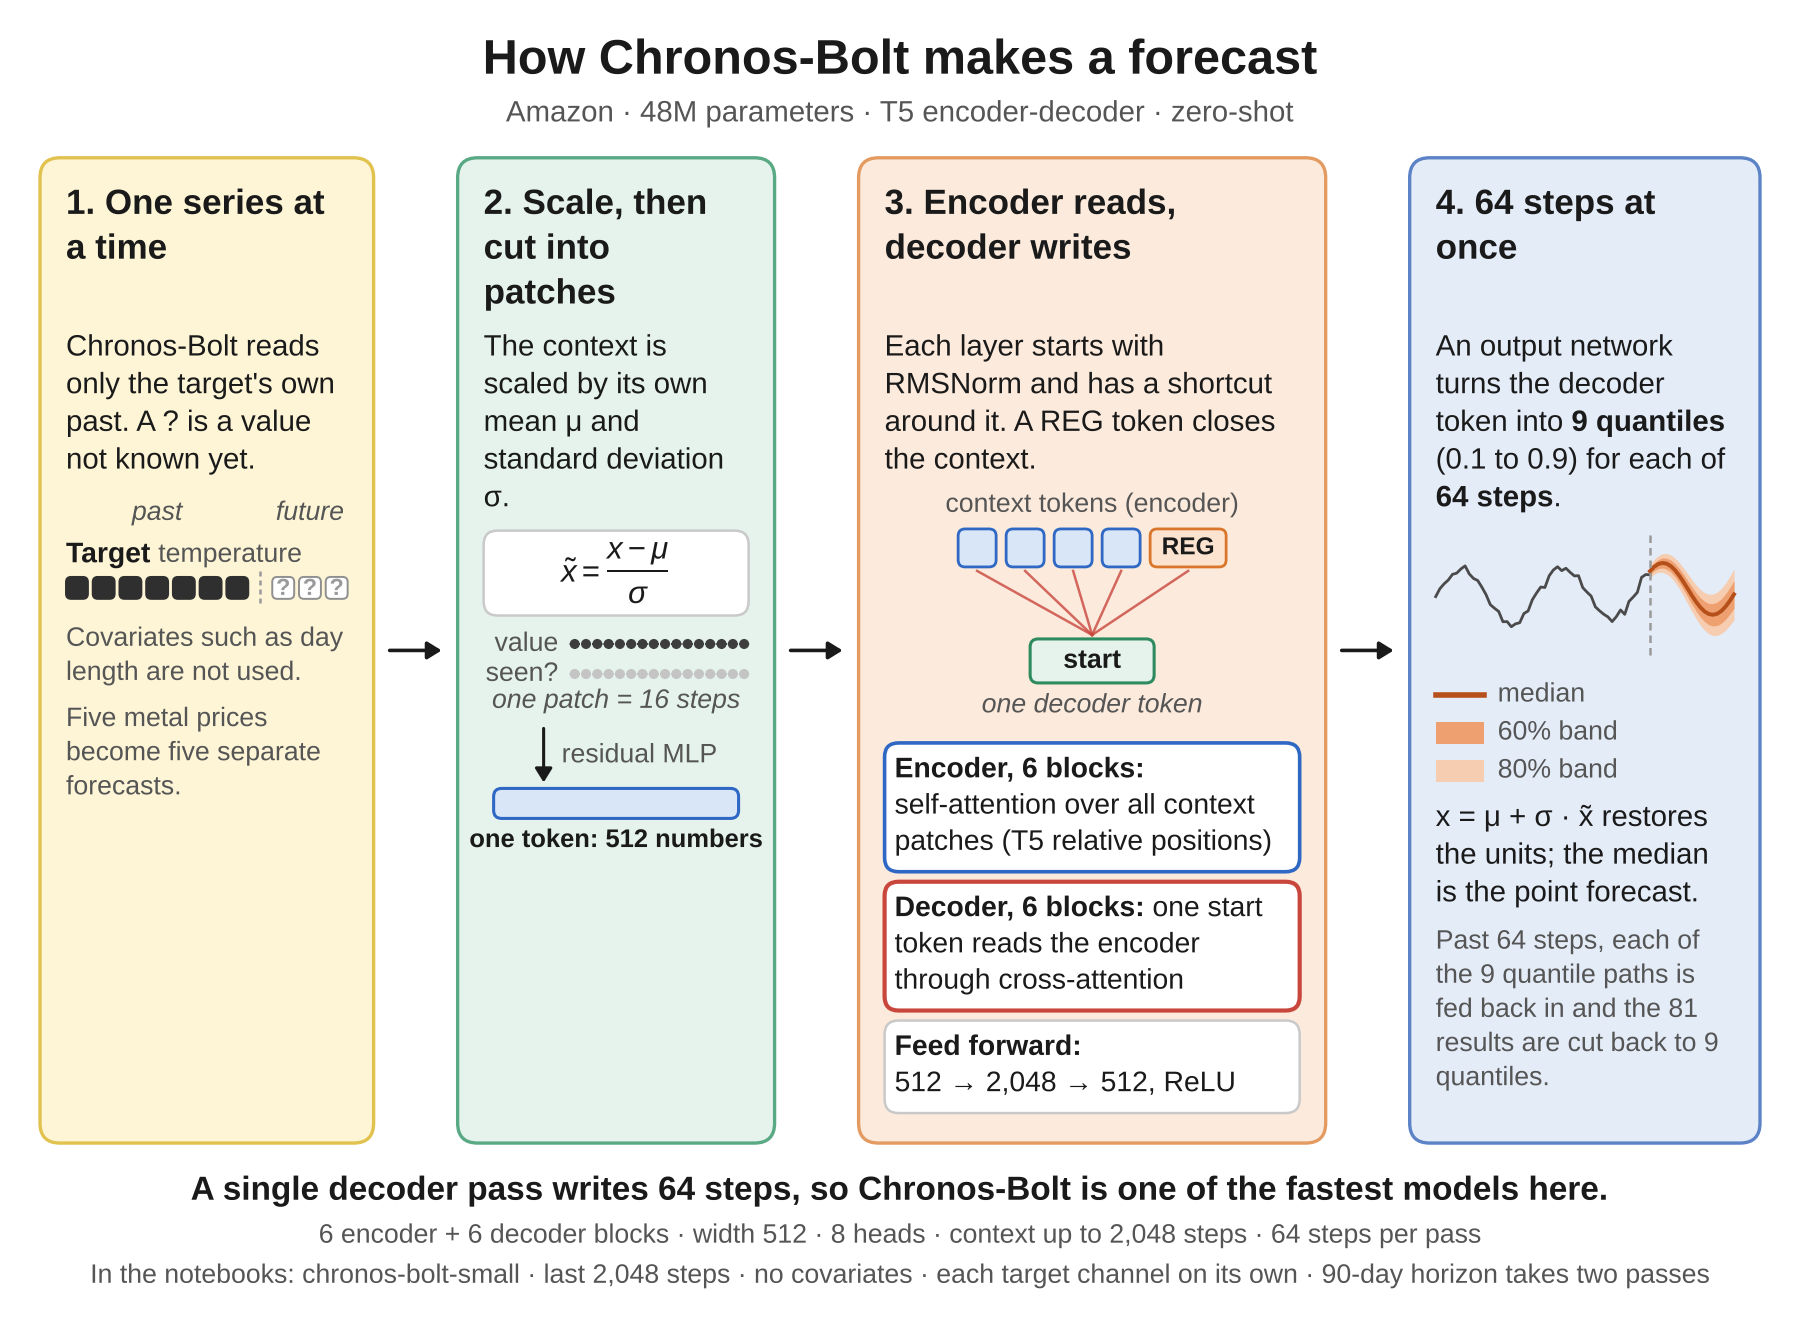

In [6]:
fig = figure("chronos-bolt", path=FIG / "chronos-bolt.png")

#### The maths behind the figure

The figure names the model's main components. Their equations follow, in the order in which the data passes through them.

**Instance normalisation** puts every series on the same scale, using the mean $\mu$ and standard deviation $\sigma$ of its own context (in the causal versions, of the values seen so far):

$$\tilde{x}_ t=\frac{x_t-\mu}{\sigma}$$

The forecast is mapped back to the original units with $x=\mu+\sigma\tilde{x}$.

**Patching** cuts the series into windows of $P$ steps, and each window becomes one token:

$$p_i=(\tilde{x}_ {(i-1)P+1},\dots,\tilde{x}_ {iP})$$

A context of $T$ steps then gives $T/P$ tokens, so attention costs $(T/P)^2$ instead of $T^2$.

The **patch embedding** turns each patch (with its missing-value mask, where the model has one) into a vector of width $d$, the token the transformer works on:

$$h_i=\mathrm{MLP}(p_i)$$

The map is a small fully connected network, a multilayer perceptron (MLP).

The **quantile head** has one output per quantile level $\tau$. Training minimises the pinball loss $\rho_\tau$ of the error $u=y-\hat{q}_ \tau$:

$$\rho_\tau(u)=\max(\tau u,\thinspace(\tau-1)u)$$

Minimising this loss makes each output the $\tau$-quantile of the forecast distribution. The median ($\tau=0.5$) is the point forecast scored in this chapter.

**RMSNorm** divides each token vector $h$ by its root mean square and multiplies the result by a learned gain $g$:

$$\frac{h}{\sqrt{\frac{1}{d}\sum_j h_j^2+\epsilon}}\odot g$$

Here $d$ is the width of the vector and $\epsilon$ a small constant that avoids dividing by zero. The normalisation keeps the size of the activations stable through many layers.

**T5 attention** compares each query with every key and adds a learned bias $B$ that depends on the (bucketed) distance between the two tokens:

$$\mathrm{softmax}\left(QK^{\top}+B\right)V$$

Position therefore enters as a bias rather than inside the vectors. As in the T5 language model, the scores are not divided by $\sqrt{d_k}$; that scale is folded into the initial weights. The decoder's self-attention and cross-attention use the same form.

The **feed-forward network** widens each token with $W_1$, keeps the positive part (ReLU) and projects it back with $W_2$:

$$W_2\thinspace\max(0,\thinspace W_1h)$$

It works on every token separately, after attention has mixed them.

#### What it costs to run

The encoder's self-attention costs O(N² · d) for N = T/16 patches (at most 128), and the decoder reads them once for every 64-step chunk of the forecast. It is among the fastest models here on a CPU. The loaded network has 47.7M parameters.

#### Covariates

Without fine-tuning, Chronos-Bolt (small) reads no covariates: it forecasts each series on its own.

#### Where the figure comes from

The figure was checked against the model's paper, its released code and configuration, and the code this chapter
runs. The main sources for its components:

| Component in the figure | Source |
|---|---|
| patch-based T5 encoder-decoder, direct multi-step quantiles | chronos-bolt model card; Ansari et al. 2024 |
| context 2048, patch 16, prediction length 64, 9 quantiles, REG token | config.json chronos_config |
| standardisation with nanmean / nanstd | chronos 2.3.2 chronos_bolt.py InstanceNorm |
| decoder input is a single start token; output block 512 → 576 = 64 × 9 | chronos_bolt.py decode; module tree |

#### The code

This chapter's adapter for Chronos-Bolt (small) is the class `ChronosBolt` in [`src/ch03_zeroshot/models/chronos.py`](../src/ch03_zeroshot/models/chronos.py) (line 81): it loads the checkpoint [`amazon/chronos-bolt-small`](https://huggingface.co/amazon/chronos-bolt-small), hands the model our context (and the covariates it can read) and turns its output into quantiles. All adapters share the interface `ZeroShotForecaster` in [`models/base.py`](../src/ch03_zeroshot/models/base.py), and `run_model` in [`runner.py`](../src/ch03_zeroshot/runner.py) runs it over every dataset, horizon and window. The network itself, layer by layer, is implemented in the `chronos-forecasting` 2.3.2 library ([PyPI page](https://pypi.org/project/chronos-forecasting/2.3.2/)). The figure above is drawn by [`architectures.py`](../src/ch03_zeroshot/architectures.py).

In [7]:
forecast("chronos-bolt")

Loading weights:   0%|          | 0/143 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 143/143 [00:00<00:00, 5644.24it/s]

Chronos-Bolt (amazon/chronos-bolt-small): 47.7M parameters, loaded in 0.6 s


,status,seconds,covariates read,notes
dataset,,,,
B1,ran,2.7,none,
B2,ran,15.0,none,


## 2.3 · TimesFM-2.5 (Google)

TimesFM treats a series the way a language model treats text. Each patch of 32 steps is a token, a causal (decoder-only) transformer reads the tokens in time order, and the output at the last token predicts the next 128 steps. Version 2.5 adds a running normalisation that uses only past values, normalisation of the queries and keys inside attention (QK-norm) and a quantile head. Covariates are not part of the network: the library's XReg option fits a linear regression on the known-future covariates in context and combines it with the network's forecast.

#### How to read the figure

Read the figure from left to right. Its four numbered panels follow the data from the series the model reads to the forecast it returns. The bold sentence under the panels sums up what sets the model apart, and the grey lines below give its size and main settings, then how this chapter's notebooks run it.

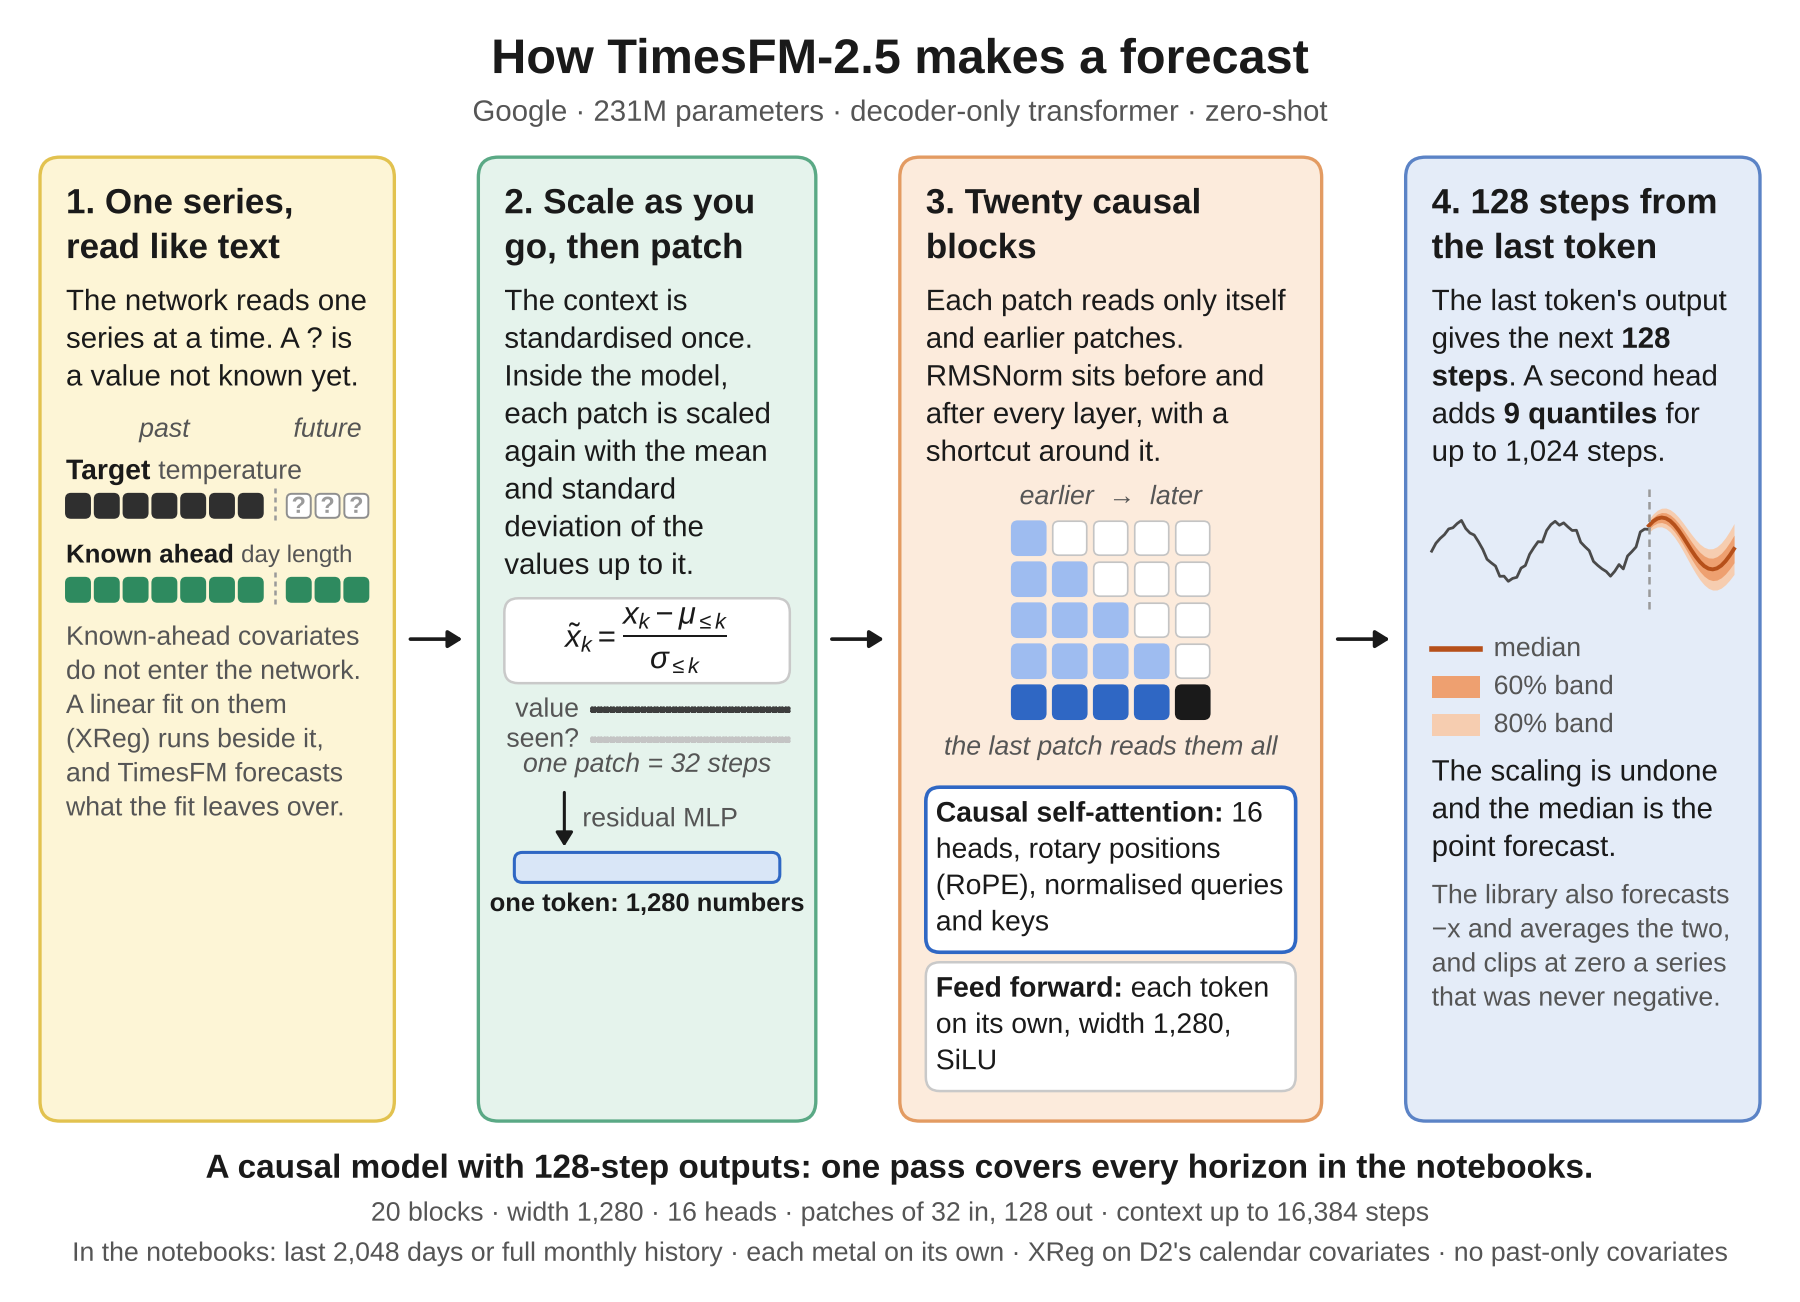

In [8]:
fig = figure("timesfm25", path=FIG / "timesfm25.png")

#### The maths behind the figure

The figure names the model's main components. Their equations follow, in the order in which the data passes through them.

**Patching** cuts the series into windows of $P$ steps, and each window becomes one token:

$$p_i=(\tilde{x}_ {(i-1)P+1},\dots,\tilde{x}_ {iP})$$

A context of $T$ steps then gives $T/P$ tokens, so attention costs $(T/P)^2$ instead of $T^2$.

**Instance normalisation** puts every series on the same scale, using the mean $\mu$ and standard deviation $\sigma$ of its own context (in the causal versions, of the values seen so far):

$$\tilde{x}_ t=\frac{x_t-\mu}{\sigma}$$

The forecast is mapped back to the original units with $x=\mu+\sigma\tilde{x}$.

The **patch embedding** turns each patch (with its missing-value mask, where the model has one) into a vector of width $d$, the token the transformer works on:

$$h_i=\mathrm{MLP}(p_i)$$

The map is a small fully connected network, a multilayer perceptron (MLP).

**RMSNorm** divides each token vector $h$ by its root mean square and multiplies the result by a learned gain $g$:

$$\frac{h}{\sqrt{\frac{1}{d}\sum_j h_j^2+\epsilon}}\odot g$$

Here $d$ is the width of the vector and $\epsilon$ a small constant that avoids dividing by zero. The normalisation keeps the size of the activations stable through many layers.

TimesFM's **attention with a per-dimension query scale** multiplies every dimension of the queries by a learned vector $s$ (PerDimScale) before the scores are computed:

$$\mathrm{softmax}\left(\frac{(s\odot Q)K^{\top}}{\sqrt{d_k}}+M\right)V$$

The queries and keys are also RMS-normalised (QK-norm) and rotated by RoPE. $M$ is $-\infty$ above the diagonal, so a patch never reads a later one. TimesFM-3's variate attention uses the same form without the causal mask.

The **feed-forward network** applies the SiLU activation, $z\thinspace\sigma(z)$, between two projections, to every token separately:

$$W_2\thinspace\mathrm{SiLU}(W_1h)$$

#### What it costs to run

The transformer costs O(L · N² · d) for N = T/32 tokens and L = 20 layers. A horizon longer than 128 steps needs one extra decoding pass for every further 128 steps. The loaded network has 231.3M parameters.

#### Covariates

Without fine-tuning, TimesFM-2.5 can read known-future covariates, but not past-only ones. It forecasts each target series on its own. The covariates do not enter the network: the library's XReg option fits a linear regression on them for each series, in context, and combines it with the network's forecast.

#### Where the figure comes from

The figure was checked against the model's paper, its released code and configuration, and the code this chapter
runs. The main sources for its components:

| Component in the figure | Source |
|---|---|
| decoder-only, input patch 32, output patch 128 | Das et al. 2024, Sec. 4 and Fig. 1 |
| 20 layers, hidden 1280, 16 heads of 80, context 16384 | config.json |
| tokenizer residual block on [values, mask] 64 → 1280 | module tree; timesfm_2p5_torch.py forward |
| pre and post RMSNorm around attention and FFN; QK RMSNorm; RoPE; PerDimScale | module tree |
| running per-patch mean/sd normalisation (revin with running stats) | timesfm_2p5_torch.py decode |
| XReg covariates = in-context linear regression | timesfm README, covariates section |

#### The code

This chapter's adapter for TimesFM-2.5 is the class `TimesFM25` in [`src/ch03_zeroshot/models/timesfm.py`](../src/ch03_zeroshot/models/timesfm.py) (line 46): it loads the checkpoint [`google/timesfm-2.5-200m-pytorch`](https://huggingface.co/google/timesfm-2.5-200m-pytorch), hands the model our context (and the covariates it can read) and turns its output into quantiles. All adapters share the interface `ZeroShotForecaster` in [`models/base.py`](../src/ch03_zeroshot/models/base.py), and `run_model` in [`runner.py`](../src/ch03_zeroshot/runner.py) runs it over every dataset, horizon and window. The network itself, layer by layer, is implemented in the `timesfm` 3.0.2 library ([PyPI page](https://pypi.org/project/timesfm/3.0.2/)). The figure above is drawn by [`architectures.py`](../src/ch03_zeroshot/architectures.py).

In [9]:
forecast("timesfm25")

TimesFM-2.5 (google/timesfm-2.5-200m-pytorch): 231.3M parameters, loaded in 3.2 s


,status,seconds,covariates read,notes
dataset,,,,
B1,ran,28.7,none,
B2,ran,62.4,none,


## 2.4 · TimesFM-3 (Google)

TimesFM-3 keeps the decoder-only patch design of TimesFM and adds variate attention, so one model reads several targets and covariates together. Each token carries its own input patch and, for a known-future covariate, also that covariate's values over the next output patch. No paper describes the model yet, so the description here comes from the model card and the released code (timesfm 3.0.2).

#### How to read the figure

Read the figure from left to right. Its four numbered panels follow the data from the series the model reads to the forecast it returns. The bold sentence under the panels sums up what sets the model apart, and the grey lines below give its size and main settings, then how this chapter's notebooks run it.

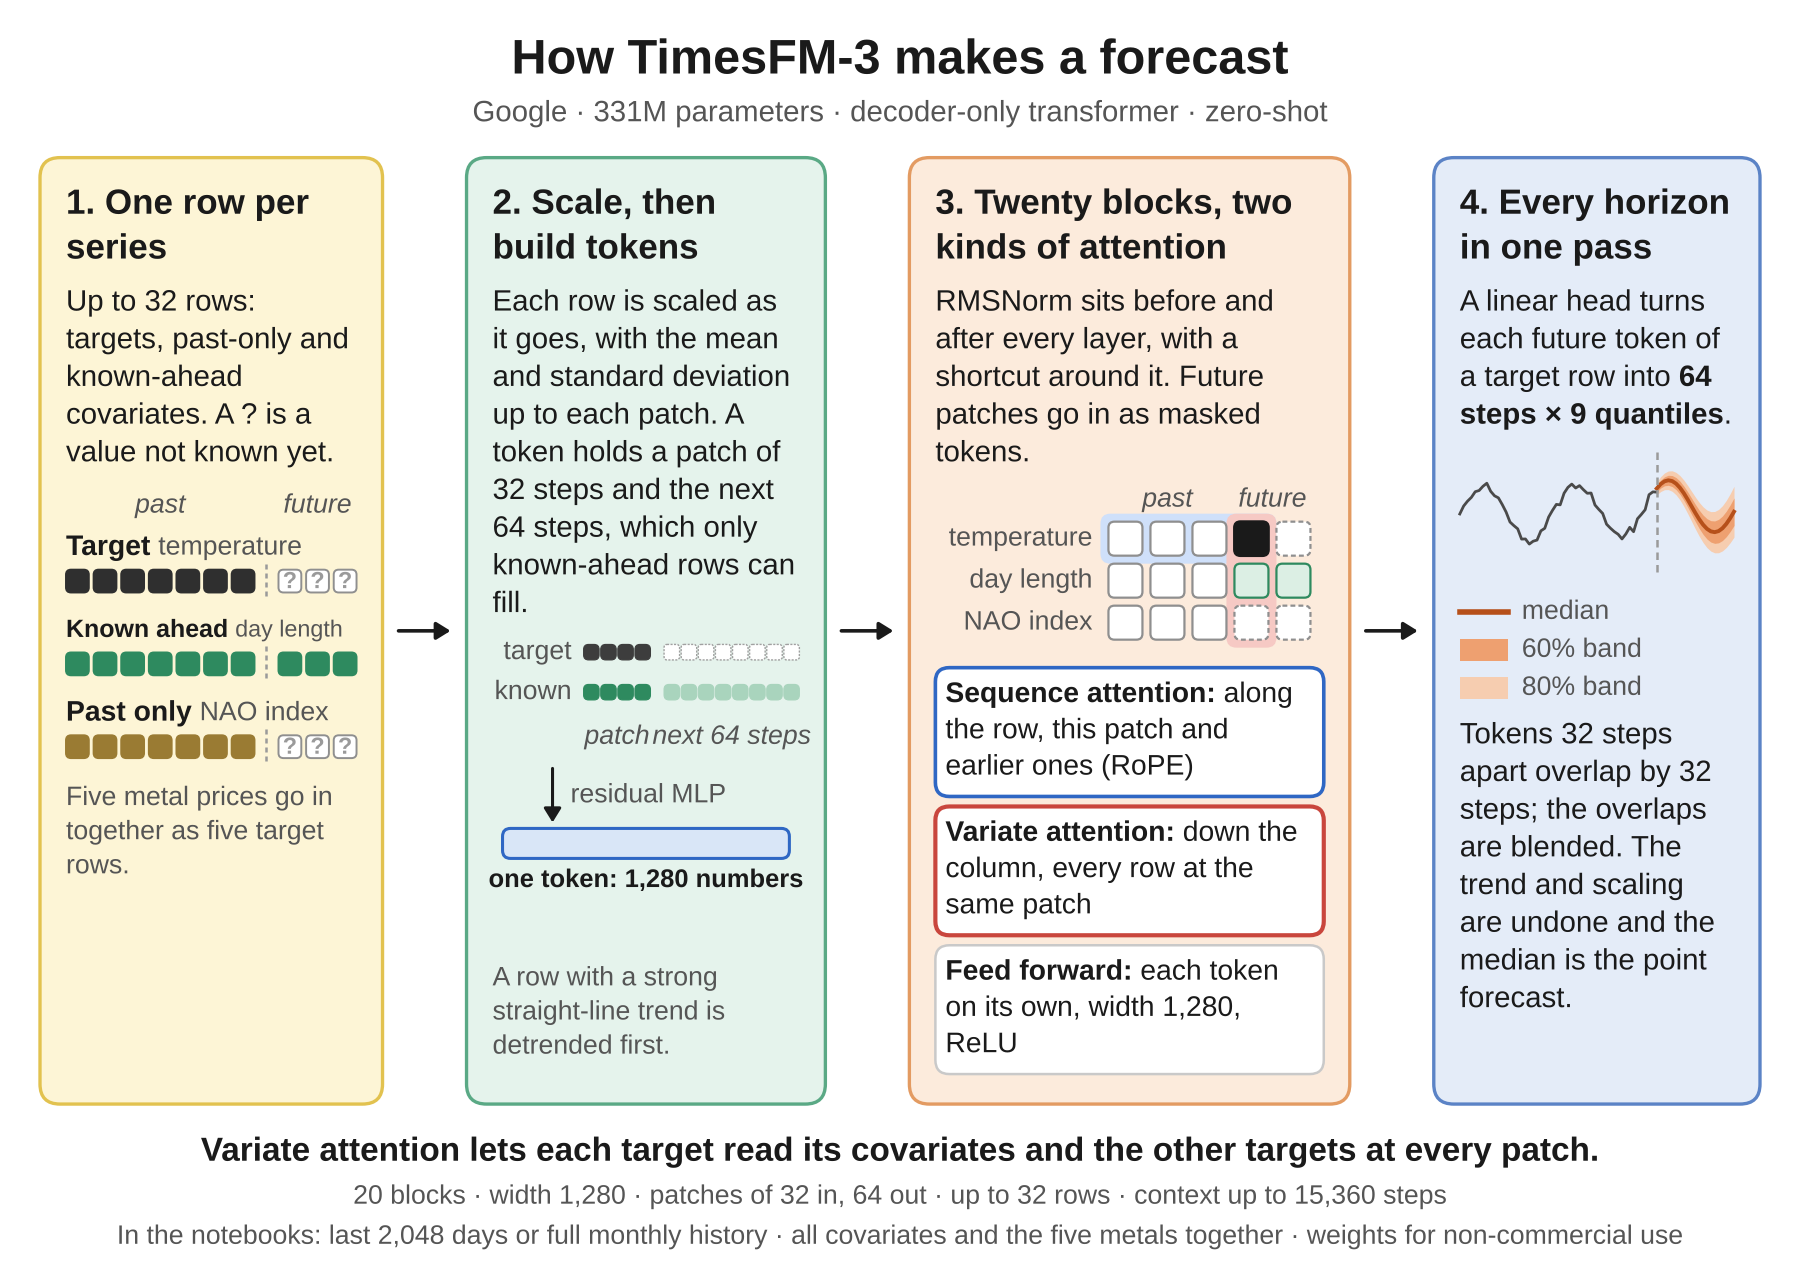

In [10]:
fig = figure("timesfm3", path=FIG / "timesfm3.png")

#### The maths behind the figure

The figure names the model's main components. Their equations follow, in the order in which the data passes through them.

**Instance normalisation** puts every series on the same scale, using the mean $\mu$ and standard deviation $\sigma$ of its own context (in the causal versions, of the values seen so far):

$$\tilde{x}_ t=\frac{x_t-\mu}{\sigma}$$

The forecast is mapped back to the original units with $x=\mu+\sigma\tilde{x}$.

**Patching** cuts the series into windows of $P$ steps, and each window becomes one token:

$$p_i=(\tilde{x}_ {(i-1)P+1},\dots,\tilde{x}_ {iP})$$

A context of $T$ steps then gives $T/P$ tokens, so attention costs $(T/P)^2$ instead of $T^2$.

**RMSNorm** divides each token vector $h$ by its root mean square and multiplies the result by a learned gain $g$:

$$\frac{h}{\sqrt{\frac{1}{d}\sum_j h_j^2+\epsilon}}\odot g$$

Here $d$ is the width of the vector and $\epsilon$ a small constant that avoids dividing by zero. The normalisation keeps the size of the activations stable through many layers.

TimesFM's **attention with a per-dimension query scale** multiplies every dimension of the queries by a learned vector $s$ (PerDimScale) before the scores are computed:

$$\mathrm{softmax}\left(\frac{(s\odot Q)K^{\top}}{\sqrt{d_k}}+M\right)V$$

The queries and keys are also RMS-normalised (QK-norm) and rotated by RoPE. $M$ is $-\infty$ above the diagonal, so a patch never reads a later one. TimesFM-3's variate attention uses the same form without the causal mask.

The **feed-forward network** widens each token with $W_1$, keeps the positive part (ReLU) and projects it back with $W_2$:

$$W_2\thinspace\max(0,\thinspace W_1h)$$

It works on every token separately, after attention has mixed them.

#### What it costs to run

Each layer costs O(V · N² · d) for attention along time plus O(N · V² · d) for variate attention, for up to V = 32 rows. The loaded network has 330.7M parameters.

#### Covariates

Without fine-tuning, TimesFM-3 can forecast several target series jointly and read both past-only and known-future covariates. Variate attention runs across the target and covariate rows.

#### Where the figure comes from

The figure was checked against the model's paper, its released code and configuration, and the code this chapter
runs. The main sources for its components:

| Component in the figure | Source |
|---|---|
| stacked mixing transformer with variate attention and CPM iterative RevIN | model card google/timesfm-3.0-pytorch |
| input patch 32, output patch 64, 9 quantiles, max 32 variates | config.json; timesfm3/torch/configs.py |
| 20 MixingTransformer layers: seq_attn (RoPE), var_attn (no RoPE), FFN, pre+post RMSNorm | module tree |
| token = [patch values, rolled next-64 values] + masks = 192 inputs | timesfm3/torch/model.py _preprocess |
| head Linear 1280 → 576 = 64 × 9 | module tree |

#### The code

This chapter's adapter for TimesFM-3 is the class `TimesFM3` in [`src/ch03_zeroshot/models/timesfm.py`](../src/ch03_zeroshot/models/timesfm.py) (line 122): it loads the checkpoint [`google/timesfm-3.0-pytorch`](https://huggingface.co/google/timesfm-3.0-pytorch), hands the model our context (and the covariates it can read) and turns its output into quantiles. All adapters share the interface `ZeroShotForecaster` in [`models/base.py`](../src/ch03_zeroshot/models/base.py), and `run_model` in [`runner.py`](../src/ch03_zeroshot/runner.py) runs it over every dataset, horizon and window. The network itself, layer by layer, is implemented in the `timesfm` 3.0.2 library ([PyPI page](https://pypi.org/project/timesfm/3.0.2/)). The figure above is drawn by [`architectures.py`](../src/ch03_zeroshot/architectures.py).

In [11]:
forecast("timesfm3")

TimesFM-3 (google/timesfm-3.0-pytorch): 330.7M parameters, loaded in 2.6 s


,status,seconds,covariates read,notes
dataset,,,,
B1,ran,6.1,none,
B2,ran,4.5,none,


## 2.5 · TiRex (NX-AI)

TiRex has no attention at all. It is built on sLSTM, the scalar-memory recurrent cell of the xLSTM family, whose running state tracks a series well over both short and long horizons. It is trained with contiguous patch masking (CPM): future patches are treated as missing inputs, so the model learns to forecast several patches at once instead of feeding its own forecasts back in.

#### How to read the figure

Read the figure from left to right. Its four numbered panels follow the data from the series the model reads to the forecast it returns. The bold sentence under the panels sums up what sets the model apart, and the grey lines below give its size and main settings, then how this chapter's notebooks run it.

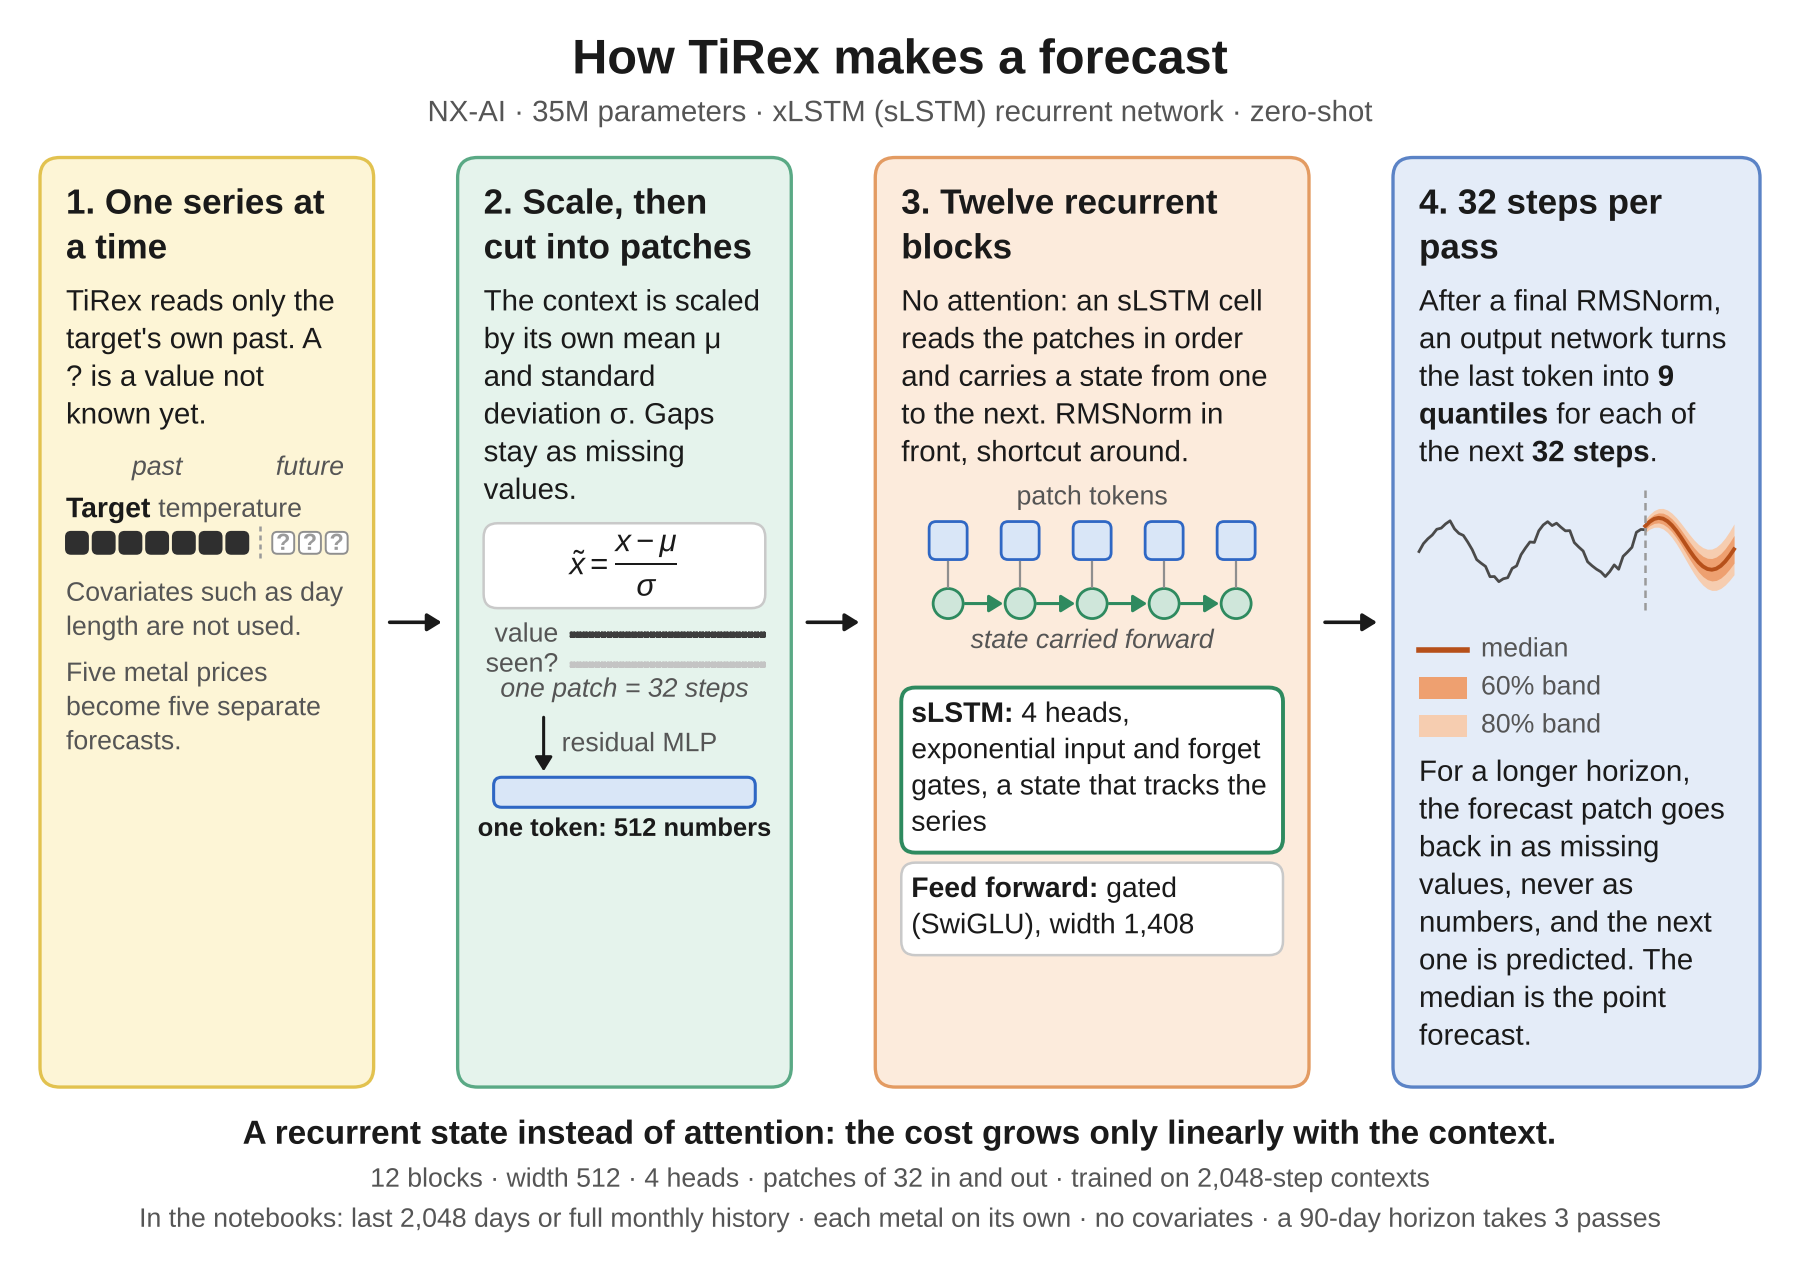

In [12]:
fig = figure("tirex", path=FIG / "tirex.png")

#### The maths behind the figure

The figure names the model's main components. Their equations follow, in the order in which the data passes through them.

**Instance normalisation** puts every series on the same scale, using the mean $\mu$ and standard deviation $\sigma$ of its own context (in the causal versions, of the values seen so far):

$$\tilde{x}_ t=\frac{x_t-\mu}{\sigma}$$

The forecast is mapped back to the original units with $x=\mu+\sigma\tilde{x}$.

**Patching** cuts the series into windows of $P$ steps, and each window becomes one token:

$$p_i=(\tilde{x}_ {(i-1)P+1},\dots,\tilde{x}_ {iP})$$

A context of $T$ steps then gives $T/P$ tokens, so attention costs $(T/P)^2$ instead of $T^2$.

The **patch embedding** turns each patch (with its missing-value mask, where the model has one) into a vector of width $d$, the token the transformer works on:

$$h_i=\mathrm{MLP}(p_i)$$

The map is a small fully connected network, a multilayer perceptron (MLP).

**RMSNorm** divides each token vector $h$ by its root mean square and multiplies the result by a learned gain $g$:

$$\frac{h}{\sqrt{\frac{1}{d}\sum_j h_j^2+\epsilon}}\odot g$$

Here $d$ is the width of the vector and $\epsilon$ a small constant that avoids dividing by zero. The normalisation keeps the size of the activations stable through many layers.

The **sLSTM cell** keeps a gated memory of the past in its cell state $c_t$, with a forget gate $f_t$, an input gate $i_t$ and a candidate value $z_t$; $n_t$ normalises the state and the output gate $o_t$ decides what is passed on:

$$c_t=f_t\thinspace c_{t-1}+i_t\thinspace z_t,\ \ h_t=o_t\thinspace c_t/n_t$$

Unlike attention, the cost grows only linearly with the context.

The **SwiGLU feed-forward network** passes one projection of the token through SiLU and uses it to gate a second projection, element by element ($\odot$), before projecting back:

$$W_2\left(\mathrm{SiLU}(W_1h)\odot W_3h\right)$$

It trains better than a plain ReLU network of the same size.

#### What it costs to run

The cost grows only linearly with the context: O(L · N · d²) for N = T/32 patches, with constant memory per step. The loaded network has 35.3M parameters.

#### Covariates

Without fine-tuning, TiRex reads no covariates: it forecasts each series on its own.

#### Where the figure comes from

The figure was checked against the model's paper, its released code and configuration, and the code this chapter
runs. The main sources for its components:

| Component in the figure | Source |
|---|---|
| xLSTM blocks with sLSTM, pre-RMSNorm residual, FFN, final RMSNorm | Auer et al. 2025, Sec. 2 and Fig. 2 |
| z-score scaling; patch embedding: values + mask through a residual block | Sec. 2 |
| contiguous patch masking (CPM) for multi-patch forecasts | Sec. 2.1 and Fig. 3 |
| gated feed forward SiLU(W_g x) ⊙ (W_u x) | tirex 1.x models/slstm/block.py FeedForward |
| 12 sLSTMBlocks, embedding 512, FFN 1408, head 512 → 288 = 32 × 9 | module tree |

#### The code

This chapter's adapter for TiRex is the class `TiRex` in [`src/ch03_zeroshot/models/tirex.py`](../src/ch03_zeroshot/models/tirex.py) (line 27): it loads the checkpoint [`NX-AI/TiRex`](https://huggingface.co/NX-AI/TiRex), hands the model our context (and the covariates it can read) and turns its output into quantiles. All adapters share the interface `ZeroShotForecaster` in [`models/base.py`](../src/ch03_zeroshot/models/base.py), and `run_model` in [`runner.py`](../src/ch03_zeroshot/runner.py) runs it over every dataset, horizon and window. The network itself, layer by layer, is implemented in the `tirex-ts` 1.4.2 library ([PyPI page](https://pypi.org/project/tirex-ts/1.4.2/)). The figure above is drawn by [`architectures.py`](../src/ch03_zeroshot/architectures.py).

In [13]:
forecast("tirex")

TiRex (NX-AI/TiRex): 35.3M parameters, loaded in 1.0 s


,status,seconds,covariates read,notes
dataset,,,,
B1,ran,0.2,none,
B2,ran,0.7,none,


## 2.6 · TiRex-2 (NX-AI)

TiRex-2 extends TiRex to several series and to covariates. Each block first mixes information along time with xLSTM, using a forward pass over the past and a reverse pass with the same weights over the known-future rows, and then mixes across series with attention whose mask stops covariates from reading the targets. The model can also update a forecast as each new value arrives, at a constant cost per step.

#### How to read the figure

Read the figure from left to right. Its four numbered panels follow the data from the series the model reads to the forecast it returns. The bold sentence under the panels sums up what sets the model apart, and the grey lines below give its size and main settings, then how this chapter's notebooks run it.

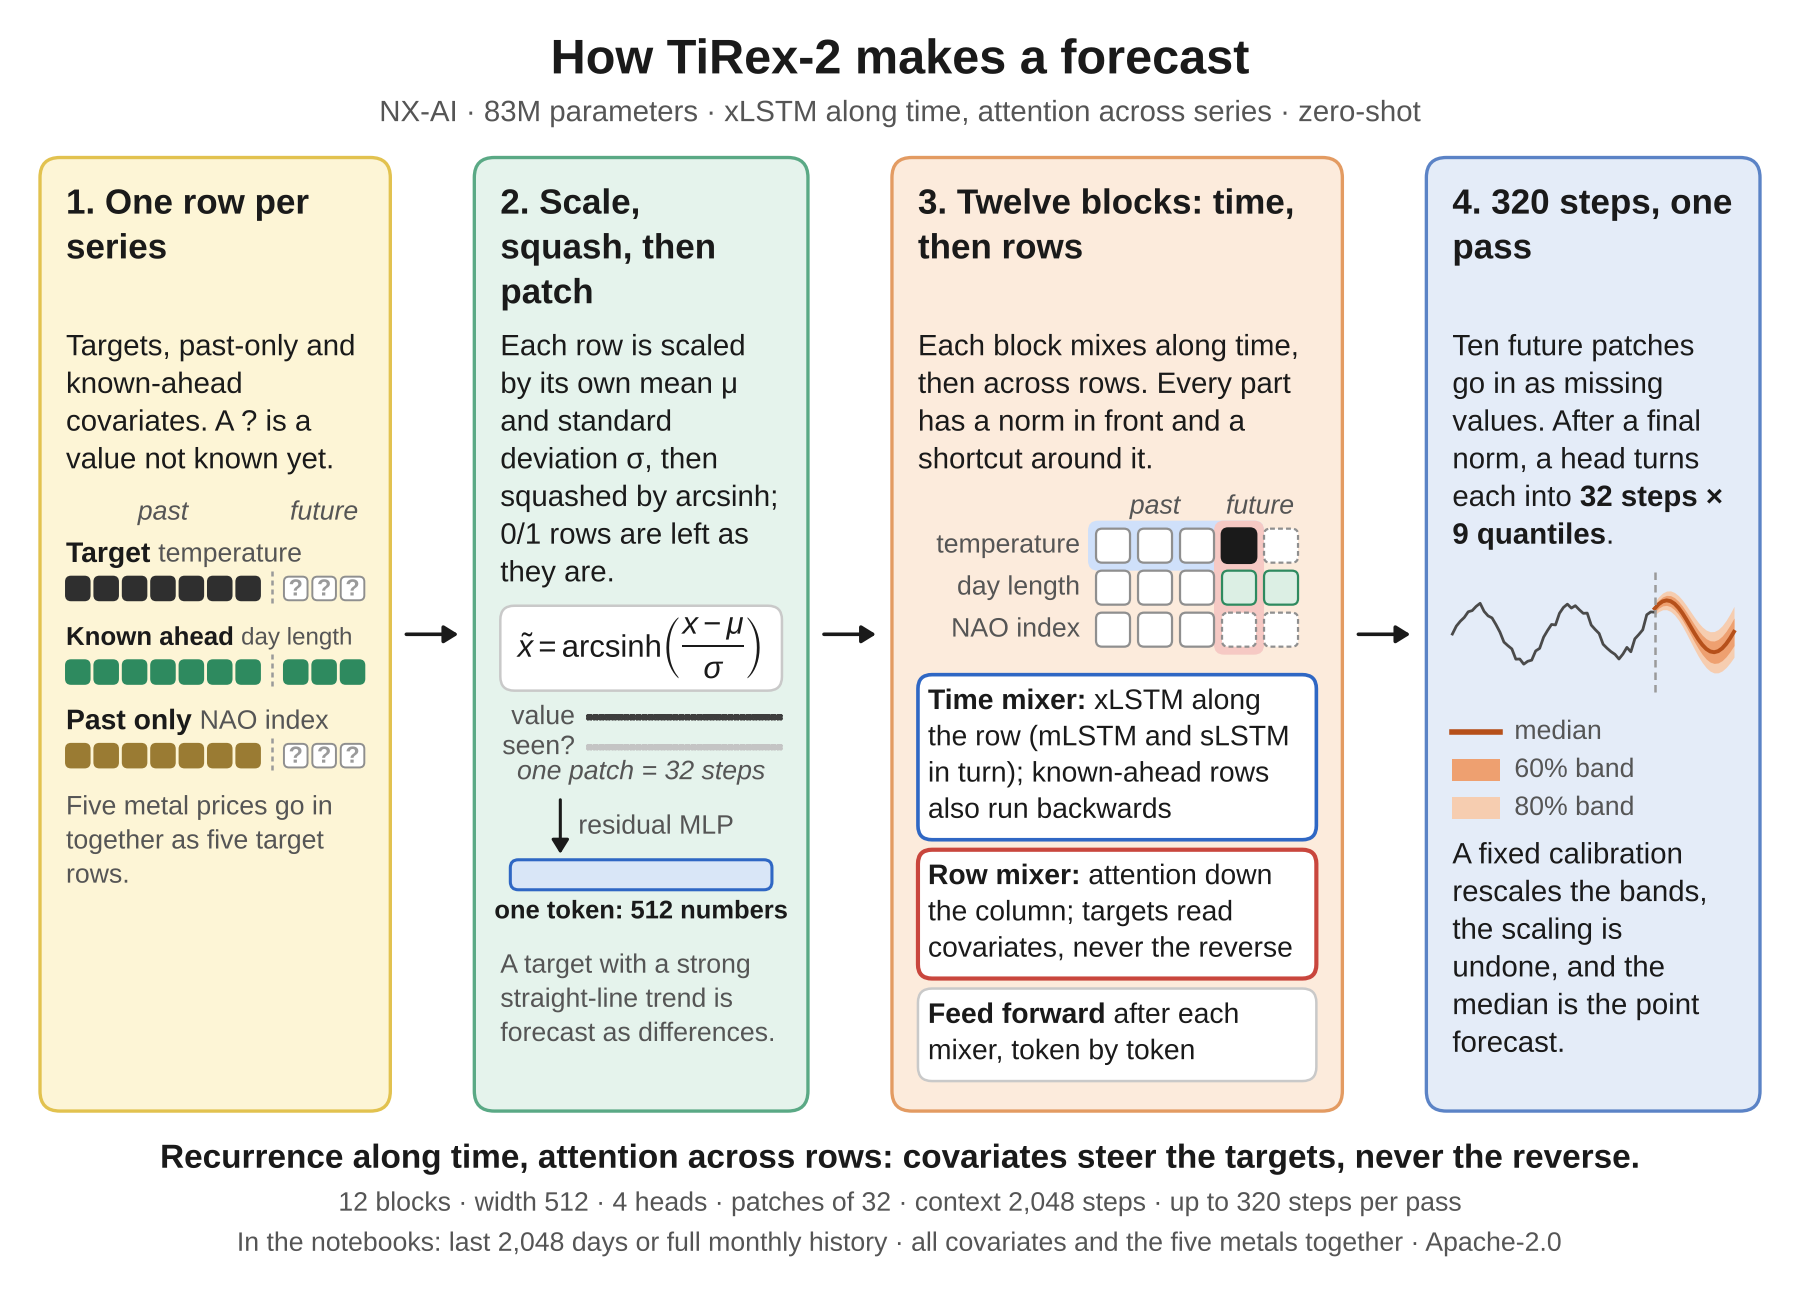

In [14]:
fig = figure("tirex2", path=FIG / "tirex2.png")

#### The maths behind the figure

The figure names the model's main components. Their equations follow, in the order in which the data passes through them.

The input is first **standardised** with the mean $\mu$ and standard deviation $\sigma$ of the context (in the causal versions, of the values seen so far), and then compressed with the **inverse hyperbolic sine** (arcsinh):

$$\tilde{x}_ t=\mathrm{arcsinh}\left(\frac{x_t-\mu}{\sigma}\right)$$

The arcsinh is close to a straight line near zero and grows like a logarithm for large values, so a few spikes cannot dominate the input.

**Patching** cuts the series into windows of $P$ steps, and each window becomes one token:

$$p_i=(\tilde{x}_ {(i-1)P+1},\dots,\tilde{x}_ {iP})$$

A context of $T$ steps then gives $T/P$ tokens, so attention costs $(T/P)^2$ instead of $T^2$.

**RMSNorm** divides each token vector $h$ by its root mean square and multiplies the result by a learned gain $g$:

$$\frac{h}{\sqrt{\frac{1}{d}\sum_j h_j^2+\epsilon}}\odot g$$

Here $d$ is the width of the vector and $\epsilon$ a small constant that avoids dividing by zero. The normalisation keeps the size of the activations stable through many layers.

The **SwiGLU feed-forward network** passes one projection of the token through SiLU and uses it to gate a second projection, element by element ($\odot$), before projecting back:

$$W_2\left(\mathrm{SiLU}(W_1h)\odot W_3h\right)$$

It trains better than a plain ReLU network of the same size.

**Masked self-attention** compares each token's query $Q$ with the keys $K$, turns the scores into weights with a softmax, and uses the weights to mix the values $V$:

$$\mathrm{softmax}\left(\frac{QK^{\top}}{\sqrt{d_k}}+M\right)V$$

The mask $M$ is $-\infty$ wherever a token may not read another: a later time step in causal attention, or an excluded pair in variate attention (covariates that may not read targets, or rows that belong to different series). Dividing by $\sqrt{d_k}$, the square root of the key width, keeps the scores in a range where the softmax does not saturate.

The **feed-forward network** applies the SiLU activation, $z\thinspace\sigma(z)$, between two projections, to every token separately:

$$W_2\thinspace\mathrm{SiLU}(W_1h)$$

#### What it costs to run

The time mixer is linear in length, O(V · N · d²); the variate mixer costs O(N · V² · d). The loaded network has 82.5M parameters.

#### Covariates

Without fine-tuning, TiRex-2 can forecast several target series jointly and read both past-only and known-future covariates. Attention across series lets the targets read the covariates but not the other way round, and a reverse xLSTM pass reads the known-future rows.

#### Where the figure comes from

The figure was checked against the model's paper, its released code and configuration, and the code this chapter
runs. The main sources for its components:

| Component in the figure | Source |
|---|---|
| alternating time mixer and variate mixer | Podest, Pichler et al. 2026, Sec. 3.2 and Fig. 2 |
| standardise + arcsinh with binary bypass | Sec. 3.2, App. C; config scaler_cfg |
| reverse, weight-tied xLSTM pass for future-known covariates, fused linearly | Sec. 3.2 |
| asymmetric group attention | Sec. 3.2, App. B |
| time-mixer FFN gated (SwiGLU); variate-mixer FFN SiLU 4 × 512; output norm T5-style (no bias, no mean subtraction) | tirex2 model/component bi_xlstm.py, attention_block.py; model-config.yaml act_func |
| 12 MultivariateBlocks alternating mLSTM / sLSTM, emb 512, patch 32 | config.json; module tree |
| maximum prediction length 320 | config future_len; tirex-2 0.3.1 warning |

#### The code

This chapter's adapter for TiRex-2 is the class `TiRex2` in [`src/ch03_zeroshot/models/tirex.py`](../src/ch03_zeroshot/models/tirex.py) (line 64): it loads the checkpoint [`NX-AI/TiRex-2`](https://huggingface.co/NX-AI/TiRex-2), hands the model our context (and the covariates it can read) and turns its output into quantiles. All adapters share the interface `ZeroShotForecaster` in [`models/base.py`](../src/ch03_zeroshot/models/base.py), and `run_model` in [`runner.py`](../src/ch03_zeroshot/runner.py) runs it over every dataset, horizon and window. The network itself, layer by layer, is implemented in the `tirex-2` 0.3.1 library ([PyPI page](https://pypi.org/project/tirex-2/0.3.1/)). The figure above is drawn by [`architectures.py`](../src/ch03_zeroshot/architectures.py).

In [15]:
forecast("tirex2")

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Fetching 2 files: 100%|██████████| 2/2 [00:00<00:00, 1515.01it/s]

TiRex-2 (NX-AI/TiRex-2): 82.5M parameters, loaded in 2.6 s


,status,seconds,covariates read,notes
dataset,,,,
B1,ran,14.4,none,
B2,ran,0.8,none,


## 3 · Results of the full runs

The tables below read the stored forecasts of every horizon and rolling window (or your own, after
`FULL_RUN = True`). The helper functions behind them (scores, tables, plots and gain tables) are in
[`src/ch03_zeroshot/report.py`](../src/ch03_zeroshot/report.py), and the metrics in
[`metrics.py`](../src/ch03_zeroshot/metrics.py).

Each model's point forecast is its median, or its mean for the models that output one. Two errors score it. The
**MASE** (mean absolute scaled error) divides the mean absolute error of the forecast by the mean absolute error
that a naive rule makes on the history up to the forecast origin $T$:

$$\mathrm{MASE} = \frac{\frac{1}{H}\sum_{h=1}^{H}\left|y_{T+h}-\hat y_{T+h}\right|}{\frac{1}{T-\ell}\sum_{t=\ell+1}^{T}\left|y_t-y_{t-\ell}\right|}.$$

The naive rule repeats the value from $\ell$ steps earlier: the last value for oil and yields ($\ell = 1$).
A MASE below 1 means that the model's errors were smaller than the errors the naive rule made on the history. The
**RMSE**, the root mean squared error, squares the errors before averaging, so it punishes large misses more.

Notebook B11 adds more metrics and compares every model of the chapter. This section looks
only at the models of this notebook, next to the naive and seasonal naive forecasts.

#### MASE by dataset and horizon

The best value in each row is in bold.

In [16]:
fc = load_forecasts(ROOT, MODELS + ["naive", "snaive"], DATASETS)
agg = aggregate(scores_cached(ROOT, MODELS + ["naive", "snaive"], DATASETS))
show_horizon_table(agg, "MASE", MODELS + ["naive", "snaive"], NAMES)

#### RMSE by dataset and horizon

The same table for the root mean squared error. Squaring the errors before averaging makes the RMSE weigh large
misses more than the MASE does, so a model that is usually close but sometimes far off looks worse here. To average over the five Treasury maturities, whose yields differ in level and volatility,
the mean squared error (MSE) of the forecast is divided by the mean squared error of the naive rule on the history,
and the square root of the ratio is taken. The result is the root mean squared scaled error (RMSSE), whose weighted
form was the accuracy metric of the M5 forecasting competition:

$$\mathrm{MSE} = \frac{1}{H}\sum_{h=1}^{H}\left(y_{T+h}-\hat y_{T+h}\right)^2, \qquad \mathrm{MSE}_ {\text{naive}} = \frac{1}{T-\ell}\sum_{t=\ell+1}^{T}\left(y_t-y_{t-\ell}\right)^2,$$

$$\mathrm{RMSSE} = \sqrt{\mathrm{MSE} / \mathrm{MSE}_ {\text{naive}}}.$$

Below 1 again means smaller errors than the naive rule made on the history. Notebook B11 shows
the RMSE in the units of the data for every series.

In [17]:
show_horizon_table(agg, "RMSSE", MODELS + ["naive", "snaive"], NAMES)

#### Actual values against the forecasts

There is one figure per dataset, with one row of panels per series (all five yields on B2) and one panel per horizon. Each
panel shows the recent history (grey), what actually happened (black) and the point forecast of each model, all from
the same test window. Window 1 is the most recent one and ends at the last observation, so the longer horizons
start further back in time. To show fewer series, change `SERIES` (for example to `"y10"` for one maturity of the yield curve); to look at an older
window, change `WINDOW` (there are 5 rolling windows per horizon).

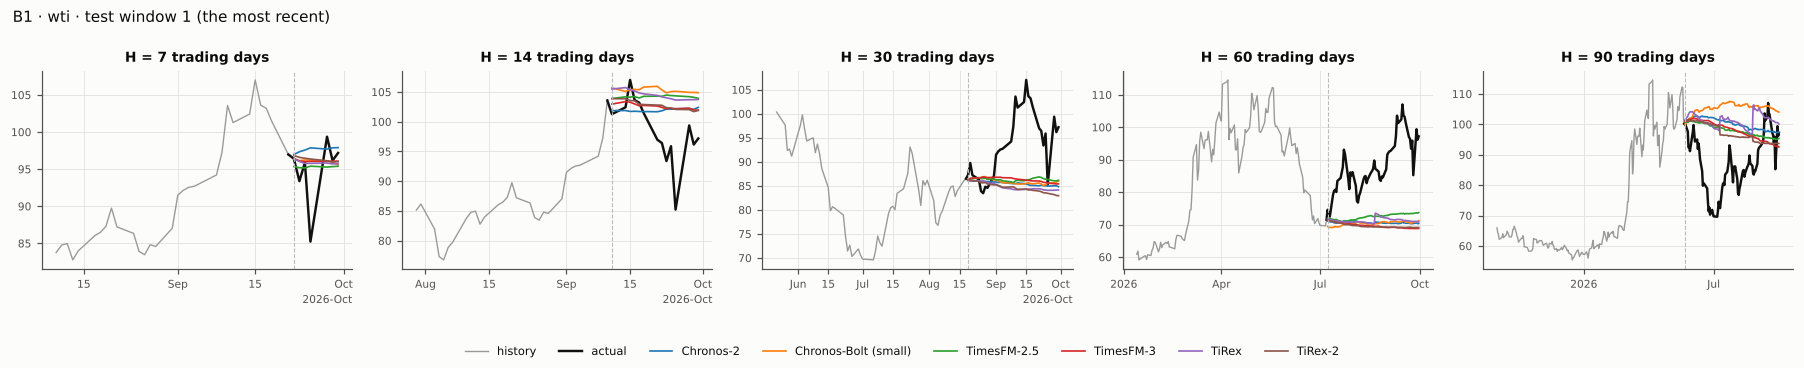

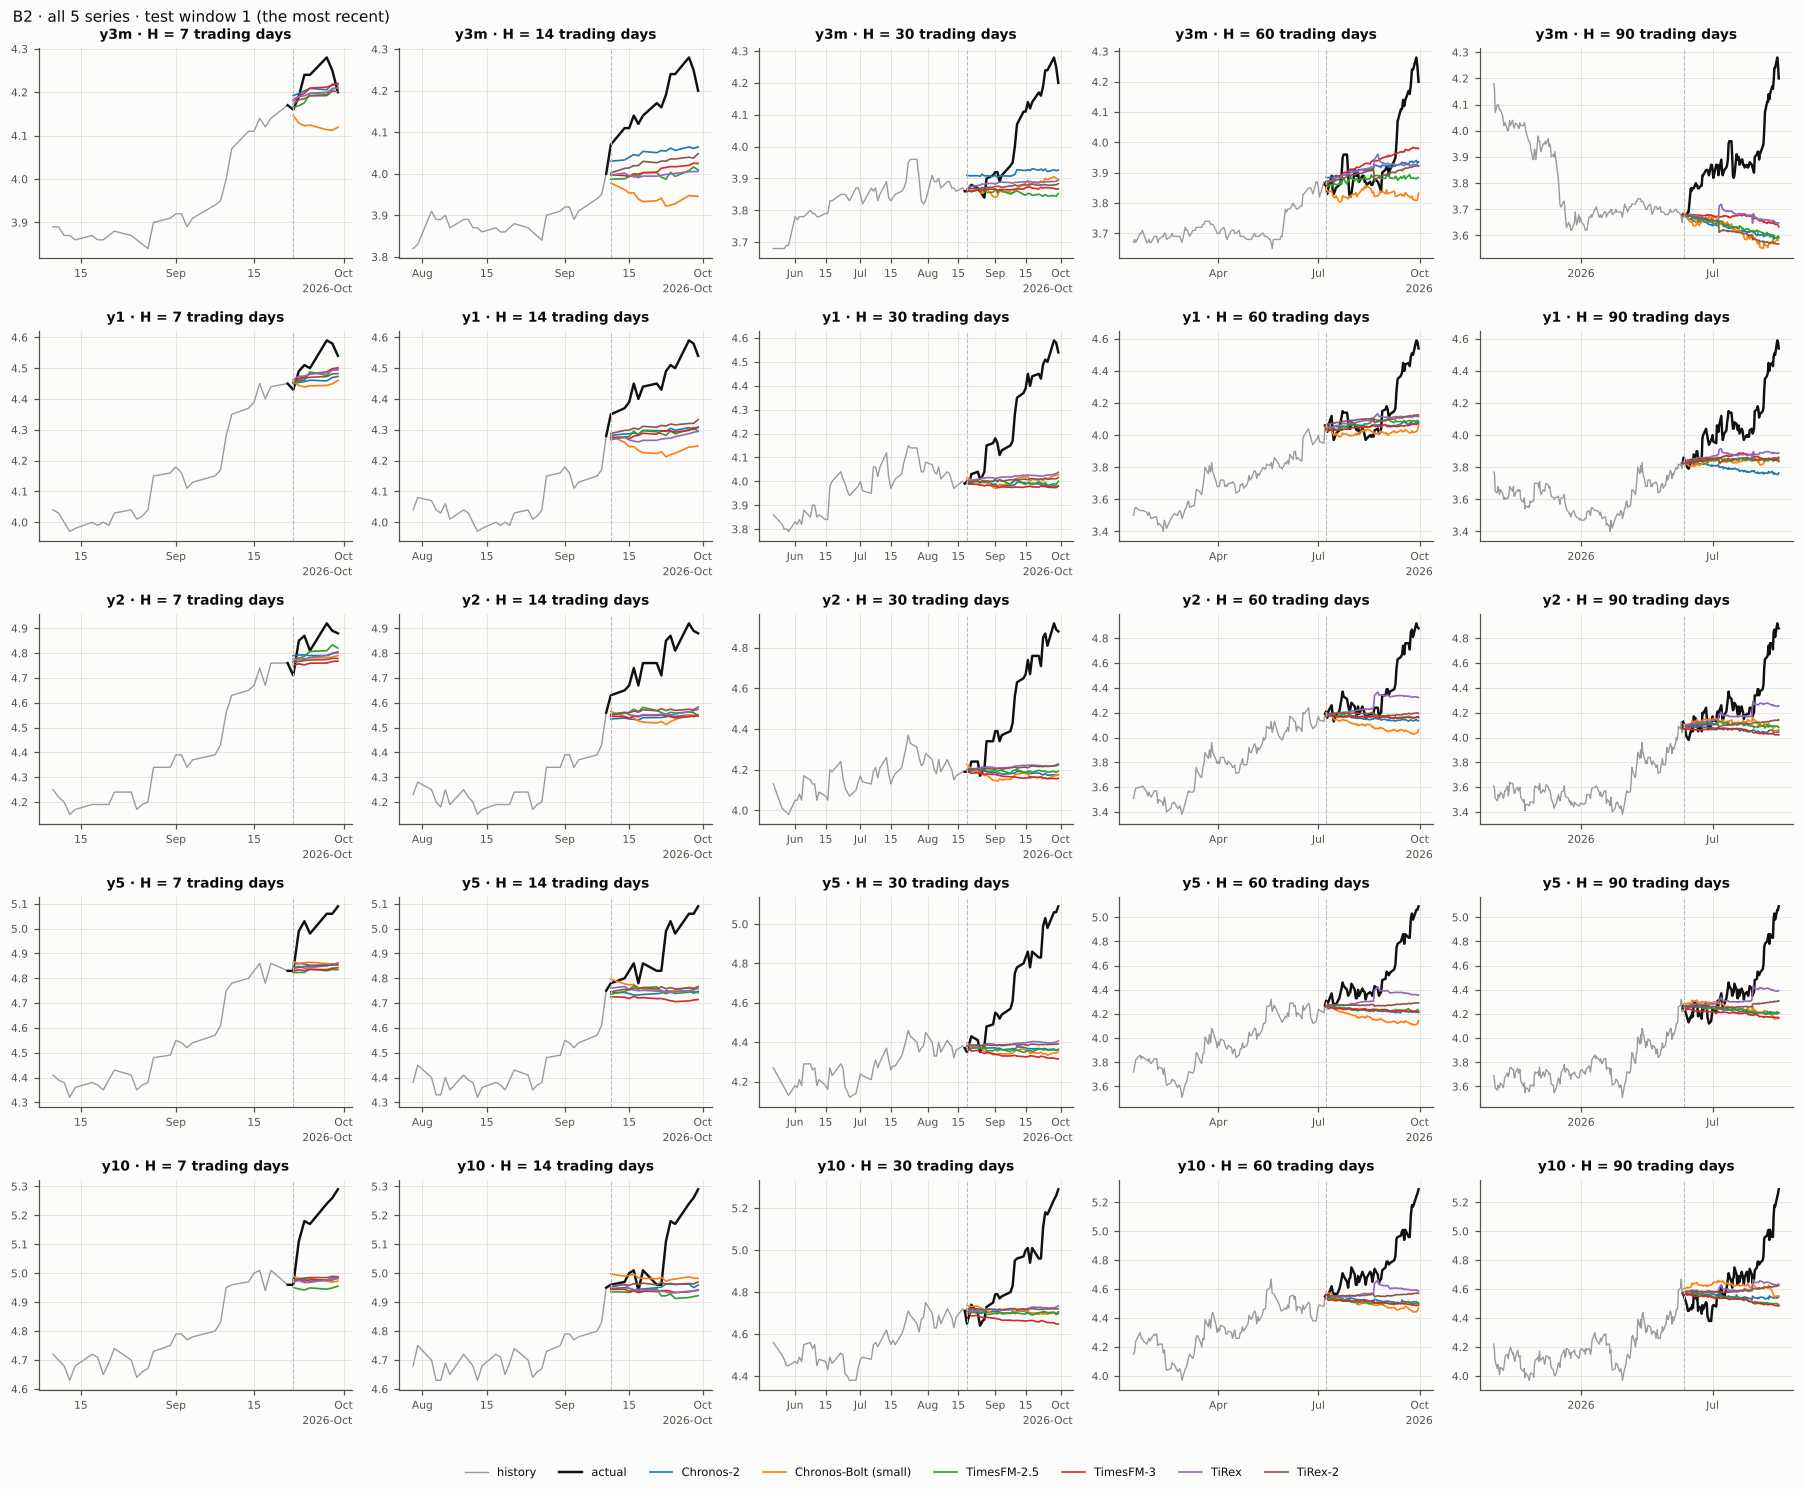

In [18]:
# the series to show: "all", one name or a list of names;
# B2 holds the Treasury yields y3m, y1, y2, y5 and y10
SERIES = {"B1": "wti", "B2": "all"}
WINDOW = 1  # 1 = the most recent test window
frames = {d: load_frame(ROOT, d) for d in DATASETS}
figs = forecast_gallery(fc, frames, SERIES, MODELS, NAMES, window=WINDOW)

#### The forecasts in numbers

For each dataset, the table shows the actual values and every model's point forecast at one horizon of the same test window, with the naive and seasonal naive rules as baselines.
`SERIES` and `WINDOW` work as in the plots above, so there is one table per series; change `HORIZON` to see another
horizon. In each row the forecast closest to the actual value is in bold. The grey rows underneath summarise the
window: the MAE, the RMSE and the mean error ME = mean(actual − forecast), which is positive when the forecasts were
too low. The best value of each is in bold. One window is a small sample, so these numbers can rank the models
differently from the averages over all windows in the tables above. Every horizon of the window is saved as a CSV
file in `results/tables/forecast_vs_actual/`.

In [19]:
HORIZON = {"B1": 14, "B2": 14}   # 7, 14, 30, 60 or 90 trading days
show_forecast_tables(fc, SERIES, HORIZON, MODELS + ["naive", "snaive"], NAMES, window=WINDOW, datasets=list(frames),
                     save=RESULTS / "tables" / "forecast_vs_actual" / "B05a.csv")

**B1 · wti · H = 14 trading days · test window 1** (2026-09-11 to 2026-09-30)

,actual,Chronos-2,Chronos-Bolt (small),TimesFM-2.5,TimesFM-3,TiRex,TiRex-2,Naive (RW),Seasonal naive
2026-09-11,101.27,101.87,105.70,103.90,102.95,105.49,103.87,103.57,92.55
2026-09-14,102.42,101.87,105.07,104.18,103.37,105.73,103.85,103.57,92.69
2026-09-15,107.02,101.72,105.38,104.12,103.29,105.39,103.57,103.57,94.21
2026-09-16,103.62,101.76,105.42,104.23,102.98,105.14,103.51,103.57,97.26
2026-09-17,103.21,101.72,105.37,103.98,102.67,104.84,102.94,103.57,103.57
2026-09-18,101.44,101.70,105.82,104.27,102.73,104.68,102.88,103.57,92.55
2026-09-21,96.97,101.67,105.95,104.30,102.64,104.42,102.79,103.57,92.69
2026-09-22,96.41,101.83,105.34,104.26,102.40,104.17,102.76,103.57,94.21
2026-09-23,93.38,102.12,104.85,104.48,102.17,104.01,102.35,103.57,97.26
2026-09-24,95.88,102.11,105.05,104.40,102.24,103.86,102.30,103.57,103.57


**B2 · y3m · H = 14 trading days · test window 1** (2026-09-11 to 2026-09-30)

,actual,Chronos-2,Chronos-Bolt (small),TimesFM-2.5,TimesFM-3,TiRex,TiRex-2,Naive (RW),Seasonal naive
2026-09-11,4.07,4.03,3.98,3.99,4.00,4.00,4.00,4.00,3.89
2026-09-14,4.11,4.03,3.96,3.99,4.00,4.00,4.01,4.00,3.91
2026-09-15,4.11,4.04,3.95,3.99,3.99,4.00,4.01,4.00,3.94
2026-09-16,4.14,4.05,3.95,4.00,4.00,3.99,4.02,4.00,3.95
2026-09-17,4.12,4.04,3.94,3.99,4.00,3.99,4.02,4.00,4.00
2026-09-18,4.14,4.05,3.93,4.00,4.00,3.99,4.03,4.00,3.89
2026-09-21,4.17,4.05,3.94,4.00,4.00,3.99,4.03,4.00,3.91
2026-09-22,4.16,4.06,3.94,3.99,4.01,4.00,4.03,4.00,3.94
2026-09-23,4.19,4.05,3.92,3.99,4.02,4.00,4.03,4.00,3.95
2026-09-24,4.24,4.06,3.92,4.00,4.02,4.00,4.04,4.00,4.00


**B2 · y1 · H = 14 trading days · test window 1** (2026-09-11 to 2026-09-30)

,actual,Chronos-2,Chronos-Bolt (small),TimesFM-2.5,TimesFM-3,TiRex,TiRex-2,Naive (RW),Seasonal naive
2026-09-11,4.35,4.28,4.28,4.27,4.28,4.27,4.29,4.28,4.11
2026-09-14,4.37,4.29,4.26,4.28,4.28,4.28,4.30,4.28,4.13
2026-09-15,4.39,4.29,4.25,4.28,4.27,4.27,4.30,4.28,4.15
2026-09-16,4.45,4.29,4.25,4.30,4.28,4.26,4.31,4.28,4.17
2026-09-17,4.40,4.29,4.23,4.28,4.28,4.26,4.30,4.28,4.28
2026-09-18,4.44,4.30,4.23,4.30,4.29,4.27,4.31,4.28,4.11
2026-09-21,4.45,4.30,4.22,4.29,4.29,4.27,4.31,4.28,4.13
2026-09-22,4.43,4.30,4.23,4.29,4.30,4.27,4.31,4.28,4.15
2026-09-23,4.49,4.30,4.21,4.28,4.30,4.27,4.31,4.28,4.17
2026-09-24,4.51,4.30,4.22,4.30,4.30,4.27,4.32,4.28,4.28


... (3 outputs left out)

,actual,Chronos-2,Chronos-Bolt (small),TimesFM-2.5,TimesFM-3,TiRex,TiRex-2,Naive (RW),Seasonal naive
2026-09-11,4.78,4.74,4.80,4.74,4.73,4.76,4.75,4.75,4.52
2026-09-14,4.80,4.74,4.78,4.75,4.72,4.77,4.76,4.75,4.54
2026-09-15,4.83,4.74,4.77,4.75,4.72,4.76,4.75,4.75,4.57
2026-09-16,4.86,4.73,4.78,4.77,4.73,4.75,4.76,4.75,4.61
2026-09-17,4.78,4.73,4.76,4.76,4.72,4.75,4.76,4.75,4.75
2026-09-18,4.86,4.73,4.76,4.76,4.72,4.75,4.76,4.75,4.52
2026-09-21,4.83,4.74,4.75,4.77,4.72,4.75,4.76,4.75,4.54
2026-09-22,4.83,4.74,4.75,4.75,4.72,4.75,4.77,4.75,4.57
2026-09-23,4.99,4.75,4.74,4.74,4.71,4.75,4.76,4.75,4.61
2026-09-24,5.03,4.75,4.75,4.75,4.71,4.74,4.76,4.75,4.75


**B2 · y10 · H = 14 trading days · test window 1** (2026-09-11 to 2026-09-30)

,actual,Chronos-2,Chronos-Bolt (small),TimesFM-2.5,TimesFM-3,TiRex,TiRex-2,Naive (RW),Seasonal naive
2026-09-11,4.96,4.95,5.00,4.94,4.94,4.96,4.95,4.95,4.77
2026-09-14,4.97,4.95,4.99,4.93,4.94,4.96,4.96,4.95,4.78
2026-09-15,5.00,4.95,4.99,4.93,4.94,4.95,4.96,4.95,4.80
2026-09-16,5.01,4.94,5.00,4.94,4.94,4.94,4.96,4.95,4.83
2026-09-17,4.94,4.94,4.98,4.93,4.93,4.94,4.96,4.95,4.95
2026-09-18,5.01,4.95,4.98,4.94,4.94,4.94,4.97,4.95,4.77
2026-09-21,4.96,4.95,4.98,4.95,4.94,4.94,4.96,4.95,4.78
2026-09-22,4.96,4.95,4.99,4.92,4.94,4.94,4.97,4.95,4.80
2026-09-23,5.11,4.96,4.97,4.92,4.94,4.93,4.96,4.95,4.83
2026-09-24,5.18,4.96,4.98,4.93,4.94,4.93,4.96,4.95,4.95


Every horizon of window 1 saved to /home/user/fresh/repo/Chapter03_Zero_Shot_Forecasting/results/tables/forecast_vs_actual/B05a.csv


#### What the runs cost

The time spent forecasting, in seconds, over all horizons and rolling windows on 4 CPU cores.

In [20]:
runs = run_summary(ROOT, MODELS)
cost_table(runs, DATASETS)

dataset,B1,B2
model,,
Chronos-2,9.5,45.5
Chronos-Bolt,4.8,24.0
TiRex,5.9,22.2
TiRex-2,33.9,18.2
TimesFM-2.5,22.0,103.4
TimesFM-3,11.2,52.9


## 4 · Key insights


- **Oil and yields are close to random walks, and the models know little more.** On B1 (WTI crude) only TimesFM-2.5
  beats the random walk on average, and only by 1.5% (mean MASE 9.79 against 9.94); the other five score 10.07 to
  11.24. On B2 (Treasury yields) none of the six beats it (3.39 to 4.11 against 3.35).
- **The short horizon is where they add something.** On B2 at 7 days TiRex-2 (1.84), TimesFM-2.5 (1.92) and
  Chronos-2 (1.94) beat the random walk (1.98) by 2% to 7%; from 30 days on every model is behind it, by up to 46%
  at 90 days (TimesFM-3, 6.23 against 4.27).
- **The ranking changes with the data.** Chronos-Bolt, the best of these six on temperature and metals, is the worst
  on both bonus datasets (11.24 and 4.11); TiRex-2, among the weakest of the six on temperature, comes closest to the random walk on
  yields.
- **Why the MASE values are so large.** MASE divides by the in-sample error of a one-day naive forecast, and the
  error of a 30- to 90-day forecast of a price is many times that. Read the numbers against the random walk's, not
  against 1.
- **RMSE gives the same ranking.** The order of the six models is identical by RMSE and by MASE on both datasets
  (TimesFM-2.5 first on oil, TiRex-2 first on yields), and RMSE puts every model a little closer to the random walk
  (TimesFM-2.5 2.0% better on oil instead of 1.5%; Chronos-Bolt 11% behind instead of 13%). The verdict against the
  random walk flips in only 4 of the 60 (model, horizon) cells, all within 1.5% of a tie (for example TimesFM-3 on
  oil at 14 days: 0.1% worse by MASE, 0.4% better by RMSE).

## References

- Chronos-2: Ansari et al. (2025), [arXiv:2510.15821](https://arxiv.org/abs/2510.15821); [model card](https://huggingface.co/amazon/chronos-2)
- Chronos-Bolt (small): Ansari et al. (2024), [arXiv:2403.07815](https://arxiv.org/abs/2403.07815); [model card](https://huggingface.co/amazon/chronos-bolt-small)
- TimesFM-2.5: Das et al. (2024), [arXiv:2310.10688](https://arxiv.org/abs/2310.10688); timesfm 2.x README; [model card](https://huggingface.co/google/timesfm-2.5-200m-pytorch)
- TimesFM-3: [model card](https://huggingface.co/google/timesfm-3.0-pytorch) (no paper yet)
- TiRex: Auer et al. (2025), [arXiv:2505.23719](https://arxiv.org/abs/2505.23719); [model card](https://huggingface.co/NX-AI/TiRex)
- TiRex-2: Podest, Pichler et al. (2026), [arXiv:2607.01204](https://arxiv.org/abs/2607.01204); [model card](https://huggingface.co/NX-AI/TiRex-2)
- Raschka, S. (2024). *Build a Large Language Model (From Scratch)*. Manning, ISBN 978-1-63343-716-6. Code: [github.com/rasbt/LLMs-from-scratch](https://github.com/rasbt/LLMs-from-scratch)
- Hyndman, R. J., & Koehler, A. B. (2006). Another look at measures of forecast accuracy. *International Journal of Forecasting*, 22(4), 679-688 (MASE). [doi:10.1016/j.ijforecast.2006.03.001](https://doi.org/10.1016/j.ijforecast.2006.03.001)